# Classificazione di Nuclei Galattici Attivi (AGN) come traccia osservativa di Buchi Neri Supermassicci — un approccio di Machine Learning

**Dataset:** costruito ad hoc tramite query SQL su SDSS (Sloan Digital Sky Survey, Data Release 19) via CasJobs, unendo dati fotometrici (`PhotoObjAll`), spettroscopici (`SpecObjAll`) e morfologici (`ZooSpec`, catalogo Galaxy Zoo 1). Campione di **400.000 osservazioni grezze**.

**Obiettivo:** un buco nero supermassiccio (SMBH) non emette luce propria e non può essere osservato direttamente. Ciò che si osserva è il suo effetto sull'ambiente circostante quando accresce materia: il nucleo della galassia diventa estremamente luminoso, un fenomeno chiamato **AGN (Active Galactic Nucleus)**. Il progetto costruisce un modello di classificazione binaria che, a partire da proprietà osservabili di una galassia (colore fotometrico, redshift, dispersione di velocità stellare, morfologia), predice se il suo nucleo ospita un buco nero supermassiccio attivo (AGN) oppure no.

**Riferimenti scientifici:**
- Kauffmann et al., *The host galaxies of active galactic nuclei*, MNRAS, 2003 — introduce la classificazione spettroscopica AGN/star-forming su campione SDSS tramite diagramma BPT, il criterio alla base della colonna `subClass` usata qui come target.
- Lintott et al., *Galaxy Zoo 1: data release of morphological classifications for nearly 900 000 galaxies*, MNRAS, 2011 — descrive il progetto di citizen science da cui provengono le probabilità morfologiche (`p_el`, `p_cs`, `p_mg`) usate come feature; il catalogo copre esattamente 893.212 galassie, un tetto che nessuna query più grande può superare.
- Abazajian et al., *The Seventh Data Release of the Sloan Digital Sky Survey*, ApJS, 2009 — definisce i limiti di completezza fotometrica per banda, usati nella sezione di pulizia dati.
- Chen & Guestrin, *XGBoost: A Scalable Tree Boosting System*, 2016.

**Struttura del progetto:**
1. Setup e installazione librerie
2. Contesto scientifico: cos'è un AGN e perché è la firma di un SMBH
3. Caricamento del dataset
4. Esplorazione iniziale (EDA) e qualità dei dati grezzi
5. Pulizia dei dati (duplicati, misure invalide, qualità fotometrica, valori mancanti)
6. Feature engineering: colori fotometrici
7. Definizione della variabile target
8. Analisi esplorativa sul dataset pulito
9. Suddivisione train/validation/test
10. Preprocessing e normalizzazione
11. Funzione di valutazione comune
12. Modello baseline: Logistic Regression
13. Modelli avanzati: XGBoost e LightGBM
14. Cross-validation
15. Ottimizzazione degli iperparametri
16. Valutazione finale sul test set (senza morfologia)
17. La morfologia aiuta? Esperimento controllato con/senza morfologia
18. Explainable AI: SHAP
19. Discussione dei risultati
20. **Parte opzionale**: SMOTE, feature selection, stacking, calibrazione, SHAP vs Permutation Feature Importance
21. Robustness check: la dispersione di velocità è affidabile ovunque?
22. Conclusioni finali


## 1. Setup e installazione librerie

In [1]:
# Se una qualunque di queste librerie non e' gia' installata nel tuo ambiente locale, decommenta la riga seguente
# !pip install -q xgboost lightgbm shap imbalanced-learn


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

import xgboost as xgb
import lightgbm as lgb
import shap
from imblearn.over_sampling import SMOTE
from scipy.stats import spearmanr

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")


## 2. Contesto scientifico: cos'è un AGN e perché è la firma di un SMBH

Un **buco nero supermassiccio (SMBH)**, con masse tra i milioni e i miliardi di masse solari, si trova al centro della quasi totalità delle galassie massicce, inclusa la Via Lattea. Un SMBH da solo non emette luce e non può essere osservato direttamente: la sua presenza si rivela solo attraverso il suo effetto gravitazionale sull'ambiente circostante.

Quando il buco nero centrale **accresce materia** (gas e polveri che gli cadono dentro), questa si riscalda a temperature elevatissime prima di attraversare l'orizzonte degli eventi, emettendo enormi quantità di radiazione su tutto lo spettro elettromagnetico. Una galassia il cui nucleo mostra questo comportamento viene chiamata **AGN (Active Galactic Nucleus)**; nei casi più estremi e luminosi si parla di **quasar**.

La SDSS classifica automaticamente lo spettro di ogni galassia osservata, distinguendo tra nuclei attivi (`AGN`, `AGN BROADLINE`) e galassie dominate da normale formazione stellare (`STARFORMING`, `STARBURST`), sulla base delle intensità relative di alcune righe di emissione (il cosiddetto diagramma BPT, da Baldwin, Phillips & Terlevich), usando nello specifico la linea di demarcazione empirica di Kauffmann et al. (2003). Questa etichetta, già presente nel database SDSS nella colonna `subClass`, viene usata in questo progetto come **variabile target**.

Due precisazioni importanti sullo scope di questa etichetta, per evitare di sovra-interpretarla: (1) la categoria `AGN` della pipeline SDSS raggruppa insieme **Seyfert** (nuclei la cui energia è dominata in modo inequivocabile dall'accrescimento sul SMBH) e **LINER** (nuclei a bassa ionizzazione, la cui origine fisica è dibattuta in letteratura: accrescimento debole sul buco nero in alcuni casi, ma in altri casi shock interstellari o popolazioni stellari evolute senza alcun buco nero attivo coinvolto) — il target di questo progetto è quindi più precisamente "nucleo con un rapporto di righe di emissione da AGN/LINER", un buon proxy ma non una prova diretta e univoca di accrescimento su SMBH in ogni singolo caso; (2) la query richiede esplicitamente `class = 'GALAXY'`, per cui i **quasar veri e propri** (classificati separatamente da SDSS come `class = 'QSO'`, i casi in cui la luce del nucleo sovrasta completamente quella della galassia ospite) sono esclusi dal campione per costruzione — questo progetto riguarda quindi nuclei attivi ancora "annegati" nella luce della galassia ospite, non quasar conclamati.

Fatte queste precisazioni, il compito di Machine Learning consiste nel ricostruire, a partire da proprietà fotometriche, spettroscopiche e morfologiche della galassia, quella stessa distinzione — cioè, in pratica, riconoscere la firma osservativa più probabile di un buco nero supermassiccio attivo.


## 3. Caricamento del dataset

Il dataset è stato ottenuto tramite la seguente query SQL, eseguita su **CasJobs** (skyserver.sdss.org/CasJobs, contesto `DR19`, sottomessa come job asincrono data la dimensione):

```sql
SELECT TOP 400000
    p.objid,
    p.ra, p.dec,
    p.u, p.g, p.r, p.i, p.z,
    s.class, s.subClass,
    s.z AS redshift,
    s.velDisp, s.velDispErr,
    zoo.p_el, zoo.p_cs, zoo.p_mg,
    zoo.spiral, zoo.elliptical, zoo.uncertain
FROM PhotoObjAll AS p
JOIN SpecObjAll AS s ON s.bestobjid = p.objid
LEFT JOIN ZooSpec AS zoo ON zoo.objid = p.objid
WHERE s.class = 'GALAXY'
  AND s.zWarning = 0
  AND s.subClass IN ('AGN', 'AGN BROADLINE', 'STARFORMING', 'STARBURST')
```

- `PhotoObjAll` fornisce la fotometria a 5 bande (`u,g,r,i,z`).
- `SpecObjAll` fornisce classe spettroscopica, sotto-classe (target), redshift e dispersione di velocità stellare.
- Il `LEFT JOIN` con `ZooSpec` (Galaxy Zoo 1) aggiunge le probabilità morfologiche senza scartare le righe prive di corrispondenza (il catalogo Galaxy Zoo 1 copre 893.212 galassie in totale, un tetto fisso indipendente da quante righe SDSS vengono estratte).

Rispetto a una prima versione del progetto (basata su 50.000 righe), qui il campione è stato ampliato di 8 volte per aumentare la potenza statistica, in particolare sul numero assoluto di galassie AGN disponibili — la classe minoritaria, che è quella che conta davvero per rispondere alle domande di ricerca del notebook.

L'intera pulizia e preparazione dei dati avviene qui sotto, in un'unica pipeline eseguita su questo file grezzo: non è richiesto nessun file intermedio già pulito.


In [3]:
df_raw = pd.read_csv("MyTable_0609_mirko_spe.csv")
print("Dimensioni dataset grezzo:", df_raw.shape)
df_raw.head()


Dimensioni dataset grezzo: (400000, 19)


,objid,ra,dec,u,g,r,i,z,class,subClass,redshift,velDisp,velDispErr,p_el,p_cs,p_mg,spiral,elliptical,uncertain
0,1237650795146444862,146.592720,-0.760257,19.07068,17.61512,16.97374,16.57817,16.34779,GALAXY,STARFORMING,0.065024,59.47845,12.362490,0.478,0.391,0.043,0.0,0.0,1.0
1,1237650795146445031,146.628570,-0.765144,19.50005,17.59248,16.67668,16.20502,15.84654,GALAXY,STARFORMING,0.064656,123.03630,9.821034,0.340,0.642,0.000,1.0,0.0,0.0
2,1237650795683512507,146.956079,-0.342291,21.01828,18.91643,17.61294,17.03453,16.59069,GALAXY,STARFORMING,0.134830,222.81910,19.872330,0.387,0.032,0.500,0.0,0.0,1.0
3,1237650796220514489,147.329502,0.028901,17.98446,16.30686,15.52711,15.10624,14.77960,GALAXY,STARFORMING,0.048096,87.18814,9.702228,0.000,1.000,0.000,1.0,0.0,0.0
4,1237648720142336237,146.571322,-0.957207,18.54270,17.05090,16.25521,15.79538,15.45037,GALAXY,STARFORMING,0.065225,100.36880,10.874480,0.139,0.833,0.000,1.0,0.0,0.0


## 4. Esplorazione iniziale (EDA) e qualità dei dati grezzi

Prima di qualunque modellazione è necessario capire cosa contiene realmente il dataset. Le colonne sono:

**Fotometria** — `u, g, r, i, z`: luminosità della galassia in 5 filtri di colore (dall'ultravioletto vicino all'infrarosso vicino); su questa scala, valori più bassi corrispondono a un oggetto più luminoso.

**Identificazione e posizione** — `objid` (identificativo univoco), `ra, dec` (coordinate celesti): non hanno potere predittivo sul tipo fisico di oggetto e verranno escluse dalle feature.

**Spettroscopia** — `redshift` (quanto l'oggetto si allontana da noi per l'espansione dell'universo, proxy della distanza), `velDisp`/`velDispErr` (dispersione di velocità delle stelle della galassia, in km/s, e relativo errore di misura). `velDisp` è legata alla massa del buco nero centrale tramite la relazione M–σ, un risultato osservativo consolidato in letteratura.

**Target** — `class` (sempre `GALAXY`, fissato nella query, quindi non informativo) e `subClass` (`AGN`, `AGN BROADLINE`, `STARFORMING`, `STARBURST`), da cui deriveremo la variabile binaria di interesse.

**Morfologia (Galaxy Zoo)** — `p_el, p_cs, p_mg`: frazione di volontari che ha classificato la galassia come ellittica, a spirale o in fase di merger rispettivamente (valori continui tra 0 e 1, non probabilità in senso statistico rigoroso ma frazioni di consenso tra osservatori umani indipendenti); `spiral, elliptical, uncertain`: le stesse informazioni ridotte a flag binari tramite soglia, ridondanti rispetto alle prime tre e qui non utilizzate.


In [4]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 19 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   objid       400000 non-null  int64  
 1   ra          400000 non-null  float64
 2   dec         400000 non-null  float64
 3   u           400000 non-null  float64
 4   g           400000 non-null  float64
 5   r           400000 non-null  float64
 6   i           400000 non-null  float64
 7   z           400000 non-null  float64
 8   class       400000 non-null  str    
 9   subClass    400000 non-null  str    
 10  redshift    400000 non-null  float64
 11  velDisp     400000 non-null  float64
 12  velDispErr  400000 non-null  float64
 13  p_el        277316 non-null  float64
 14  p_cs        277316 non-null  float64
 15  p_mg        277316 non-null  float64
 16  spiral      277316 non-null  float64
 17  elliptical  277316 non-null  float64
 18  uncertain   277316 non-null  float64
dtypes: float64(16

In [5]:
df_raw.describe().T


,count,mean,std,min,25%,50%,75%,max
objid,400000.0,1.237662e+18,6.941673e+12,1.237646e+18,1.237658e+18,1.237662e+18,1.237666e+18,1.237681e+18
ra,400000.0,1.762675e+02,7.937451e+01,6.722101e-04,1.375875e+02,1.806286e+02,2.223725e+02,3.599951e+02
dec,400000.0,2.294156e+01,1.973815e+01,-1.584933e+01,4.490993e+00,2.088086e+01,3.844550e+01,8.427039e+01
u,400000.0,1.873821e+01,9.765874e+01,-9.999000e+03,1.878075e+01,1.938380e+01,2.017291e+01,3.177132e+01
g,400000.0,1.741776e+01,9.892199e+01,-9.999000e+03,1.749978e+01,1.808559e+01,1.873462e+01,3.100457e+01
r,400000.0,1.692614e+01,8.960254e+01,-9.999000e+03,1.687092e+01,1.745751e+01,1.799420e+01,3.199010e+01
i,400000.0,1.650260e+01,9.235587e+01,-9.999000e+03,1.649531e+01,1.708421e+01,1.764393e+01,3.210178e+01
z,400000.0,1.613384e+01,1.001698e+02,-9.999000e+03,1.624116e+01,1.684972e+01,1.749339e+01,2.918374e+01
redshift,400000.0,1.227252e-01,1.084682e-01,-1.412593e-03,5.687185e-02,8.814418e-02,1.395714e-01,5.737868e-01
velDisp,400000.0,1.172379e+02,1.350348e+02,0.000000e+00,5.583378e+01,9.095202e+01,1.337748e+02,8.500000e+02


In [6]:
n_duplicati = df_raw["objid"].duplicated().sum()
n_unici = df_raw["objid"].nunique()
print(f"Righe totali: {len(df_raw)}")
print(f"objid unici: {n_unici}")
print(f"Righe duplicate (stesso oggetto osservato più volte): {n_duplicati}")


Righe totali: 400000
objid unici: 370095
Righe duplicate (stesso oggetto osservato più volte): 29905


            n_missing  %_missing
uncertain      122684      30.67
spiral         122684      30.67
p_mg           122684      30.67
p_el           122684      30.67
p_cs           122684      30.67
elliptical     122684      30.67


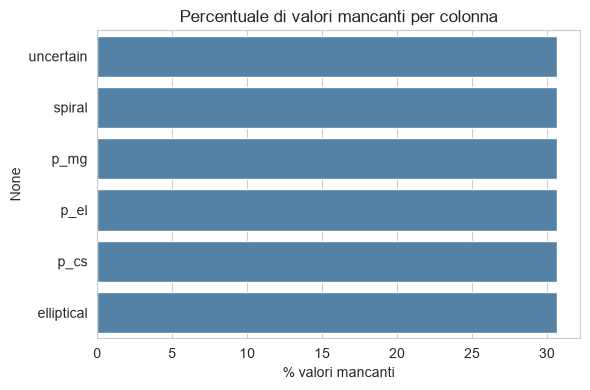

In [7]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({"n_missing": missing, "%_missing": missing_pct})
missing_df = missing_df[missing_df["n_missing"] > 0]
print(missing_df)

plt.figure(figsize=(6,4))
sns.barplot(x=missing_df["%_missing"], y=missing_df.index, color="steelblue")
plt.title("Percentuale di valori mancanti per colonna")
plt.xlabel("% valori mancanti")
plt.tight_layout()
plt.show()


### Lettura dell'EDA iniziale

Il dataset grezzo contiene **400.000 righe** ma solo **370.095 `objid` unici**: quasi 30.000 righe sono osservazioni ripetute dello stesso oggetto. Andranno deduplicate prima di allenare qualunque modello, per evitare data leakage tra training e test set.

Le uniche colonne con valori mancanti sono quelle di morfologia, come atteso dato che derivano dal `LEFT JOIN` con un catalogo (Galaxy Zoo 1) di dimensione fissa e indipendente da quante righe SDSS vengono estratte in questa query.

Come nella EDA iniziale della prima versione del progetto, le magnitudini `u,g,r,i,z` mostrano una deviazione standard anomala, sintomo degli stessi problemi di qualità fotometrica già identificati in precedenza — affrontati sistematicamente nella sezione di pulizia.


## 5. Pulizia dei dati

### 5.1 Duplicati

Per ogni `objid` ripetuto si sceglie di tenere l'osservazione con `velDispErr` più basso, cioè la misura spettroscopica più precisa tra quelle disponibili per lo stesso oggetto, scartando le altre.


In [8]:
df_sorted = df_raw.sort_values("velDispErr")
df_dedup = df_sorted.drop_duplicates(subset="objid", keep="first").sort_index()
print("Righe prima della deduplicazione:", len(df_raw))
print("Righe dopo la deduplicazione:", len(df_dedup))


Righe prima della deduplicazione: 400000
Righe dopo la deduplicazione: 370095


### 5.2 Misure spettroscopiche invalide (`velDisp`, `velDispErr`)

Come discusso nella prima versione del progetto, `velDisp` = 0 indica una misura fallita, e `velDisp` ≥ 850 km/s corrisponde al bordo superiore della griglia di fit della pipeline SDSS/BOSS (idlspec2d, che esplora dispersioni di prova fino a 850 km/s in passi di 25 km/s) — non un valore fisico affidabile.

A questi si aggiungono righe con **`velDispErr` negativo**: secondo la documentazione della pipeline SDSS/BOSS, l'errore viene impostato a un valore negativo specificamente quando il best-fit cade al bordo alto della griglia di prova (lo stesso limite di 850 km/s) — è un flag esplicito di "fit inaffidabile perché al limite", non un errore di misura in senso proprio. Tutte queste righe vengono escluse.


In [9]:
n_zero = (df_dedup["velDisp"] <= 0).sum()
n_ceiling = (df_dedup["velDisp"] >= 850).sum()
n_negerr = (df_dedup["velDispErr"] < 0).sum()
print(f"Righe con velDisp <= 0: {n_zero}")
print(f"Righe con velDisp >= 850 (saturazione): {n_ceiling}")
print(f"Righe con velDispErr < 0: {n_negerr}")

before = len(df_dedup)
df_clean = df_dedup[(df_dedup["velDisp"] > 0) & (df_dedup["velDisp"] < 850) & (df_dedup["velDispErr"] >= 0)].copy()
print(f"\nRighe prima del filtro: {before}")
print(f"Righe dopo il filtro: {len(df_clean)}  (rimosse {before - len(df_clean)})")


Righe con velDisp <= 0: 28875
Righe con velDisp >= 850 (saturazione): 7174
Righe con velDispErr < 0: 7183

Righe prima del filtro: 370095
Righe dopo il filtro: 334046  (rimosse 36049)


### 5.3 Fotometria invalida (flag -9999)

Come in precedenza, si scartano le righe con magnitudine marcata dal flag di misura fallita -9999.


In [10]:
mask_valid_phot = (df_clean[["u","g","r","i","z"]] > -100).all(axis=1)
n_invalid_phot = (~mask_valid_phot).sum()
print(f"Righe con fotometria invalida (-9999): {n_invalid_phot}")

before2 = len(df_clean)
df_clean = df_clean[mask_valid_phot].copy()
print(f"Righe dopo il filtro fotometria: {len(df_clean)}  (rimosse {before2 - len(df_clean)})")


Righe con fotometria invalida (-9999): 30
Righe dopo il filtro fotometria: 334016  (rimosse 30)


### 5.4 Qualità fotometrica: oltre il flag -9999

Come identificato nella prima versione del progetto, alcune galassie hanno fotometria oltre il **limite di completezza al 95%** dichiarato dalla survey per banda (Abazajian et al. 2009: `u`<22.0, `g`<22.2, `r`<22.2, `i`<21.3, `z`<20.5), che produce colori fisicamente implausibili senza che nessun flag espliciti l'errore. Si applica lo stesso filtro combinato: limite di completezza per banda + controllo di sanità sui colori residui.


In [11]:
limits = {"u": 22.0, "g": 22.2, "r": 22.2, "i": 21.3, "z": 20.5}  # limiti di completezza al 95%, Abazajian et al. 2009

mask_depth = pd.Series(True, index=df_clean.index)
for band, lim in limits.items():
    mask_depth &= (df_clean[band] < lim)

u_g_tmp = df_clean["u"] - df_clean["g"]
g_r_tmp = df_clean["g"] - df_clean["r"]
r_i_tmp = df_clean["r"] - df_clean["i"]
i_z_tmp = df_clean["i"] - df_clean["z"]
mask_color_ok = (u_g_tmp.abs() <= 5) & (g_r_tmp.abs() <= 3) & (r_i_tmp.abs() <= 3) & (i_z_tmp.abs() <= 3)

print("Righe oltre il limite di completezza fotometrica in almeno una banda:", (~mask_depth).sum())
print("Righe con almeno un colore fuori da un range fisicamente plausibile:", (~mask_color_ok).sum())
print("  di cui già catturate dal limite di completezza:", ((~mask_color_ok) & (~mask_depth)).sum())
print("  colori estremi residui (fuori range ma dentro i limiti di completezza):", ((~mask_color_ok) & mask_depth).sum())

before3 = len(df_clean)
df_clean = df_clean[mask_depth & mask_color_ok].copy()
print(f"\nRighe dopo il filtro di qualità fotometrica: {len(df_clean)}  (rimosse {before3 - len(df_clean)})")

print("\nStatistiche di u,g,r,i,z dopo la pulizia completa:")
print(df_clean[["u","g","r","i","z"]].describe().T.round(3))


Righe oltre il limite di completezza fotometrica in almeno una banda: 36979
Righe con almeno un colore fuori da un range fisicamente plausibile: 1756
  di cui già catturate dal limite di completezza: 1630
  colori estremi residui (fuori range ma dentro i limiti di completezza): 126

Righe dopo il filtro di qualità fotometrica: 296911  (rimosse 37105)

Statistiche di u,g,r,i,z dopo la pulizia completa:
      count    mean    std     min     25%     50%     75%     max
u  296911.0  19.215  1.016  11.064  18.675  19.246  19.769  22.000
g  296911.0  17.896  1.048  11.781  17.372  17.952  18.367  22.199
r  296911.0  17.227  1.024  11.217  16.723  17.308  17.681  22.153
i  296911.0  16.849  1.026  10.712  16.340  16.924  17.304  21.295
z  296911.0  16.611  1.051   9.972  16.076  16.675  17.086  20.500


**Nota sulla scala del problema:** su questo campione più ampio, il filtro di qualità fotometrica rimuove una frazione di righe sensibilmente più alta (circa l'11%) di quanto osservato sul campione preliminare da 50.000 righe (circa l'1,2%). Questo è coerente con quanto atteso: un pull di dati più ampio e meno selezionato campiona una porzione più rappresentativa — e quindi anche più eterogenea in qualità — della popolazione di galassie SDSS, inclusa una quota maggiore di oggetti deboli vicini al limite di sensibilità della survey. Lungi dall'essere un problema, questo conferma che il controllo di qualità introdotto in questa sezione è tutt'altro che un dettaglio trascurabile su un campione di queste dimensioni.


### 5.5 Valori mancanti nella morfologia: due dataset invece di uno

Come discusso, i valori mancanti in `p_el, p_cs, p_mg` non sembrano casuali: la spiegazione più probabile è un disallineamento tra due release SDSS diverse (Galaxy Zoo 1 costruito su DR7, fotometria/spettroscopia qui usate da DR19, release in cui gli identificativi `objid` possono cambiare per via della ri-elaborazione delle immagini), anche se non è da escludere che una parte dipenda semplicemente dalla copertura di cielo o dal limite di magnitudine del campione originale di Galaxy Zoo 1, distinto da quello della query qui usata. Su questo campione più ampio ci si aspetta inoltre una quota di dati mancanti più alta per un motivo strutturale aggiuntivo: Galaxy Zoo 1 copre un numero fisso di galassie (893.212), quindi più la query SDSS si allarga, maggiore è la frazione di oggetti che cade fuori da quella copertura fissa.

Si costruiscono quindi, come nella prima versione, **due dataset puliti**: `df_clean` (tutte le righe pulite, dataset principale per le sezioni 9-16) e `df_complete` (il sottoinsieme con morfologia disponibile, usato per l'esperimento controllato della sezione 17).


In [12]:
morph_cols = ["p_el", "p_cs", "p_mg"]
n_missing_morph = df_clean[morph_cols].isna().any(axis=1).sum()
print(f"Righe senza morfologia (dopo pulizia): {n_missing_morph} su {len(df_clean)} ({n_missing_morph/len(df_clean)*100:.2f}%)")

df_complete = df_clean.dropna(subset=morph_cols).copy()
print(f"\ndf_clean (senza richiedere morfologia):   {len(df_clean)} righe")
print(f"df_complete (con morfologia disponibile): {len(df_complete)} righe")


Righe senza morfologia (dopo pulizia): 55163 su 296911 (18.58%)

df_clean (senza richiedere morfologia):   296911 righe
df_complete (con morfologia disponibile): 241748 righe


## 6. Feature engineering: colori fotometrici

Si calcolano i **colori fotometrici** `u-g`, `g-r`, `r-i`, `i-z`, come nella prima versione del progetto: differenze di magnitudine più informative delle magnitudini singole perché indipendenti dalla luminosità assoluta/distanza dell'oggetto.


In [13]:
for d in [df_clean, df_complete]:
    d["u_g"] = d["u"] - d["g"]
    d["g_r"] = d["g"] - d["r"]
    d["r_i"] = d["r"] - d["i"]
    d["i_z"] = d["i"] - d["z"]

df_complete[["u","g","r","i","z","u_g","g_r","r_i","i_z"]].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
u,241748.0,19.007,0.833,11.064,18.571,19.119,19.561,21.997
g,241748.0,17.650,0.775,11.781,17.275,17.830,18.196,20.790
r,241748.0,16.989,0.756,11.317,16.640,17.195,17.539,20.541
i,241748.0,16.613,0.757,11.050,16.262,16.812,17.159,20.470
z,241748.0,16.372,0.783,9.972,16.001,16.562,16.927,20.460
u_g,241748.0,1.357,0.280,-3.985,1.161,1.324,1.530,4.867
g_r,241748.0,0.661,0.198,-1.042,0.518,0.663,0.801,2.905
r_i,241748.0,0.376,0.090,-2.576,0.325,0.385,0.434,1.865
i_z,241748.0,0.241,0.099,-2.977,0.185,0.249,0.304,2.889


## 7. Definizione della variabile target

Come nella prima versione: `is_agn = 1` se `subClass` è `AGN` o `AGN BROADLINE`, `is_agn = 0` se `subClass` è `STARFORMING` o `STARBURST`.


In [14]:
df_clean["is_agn"] = df_clean["subClass"].isin(["AGN", "AGN BROADLINE"]).astype(int)
df_complete["is_agn"] = df_complete["subClass"].isin(["AGN", "AGN BROADLINE"]).astype(int)

print("=== df_clean (senza richiedere morfologia) ===")
print(df_clean["subClass"].value_counts())
print((df_clean["is_agn"].value_counts(normalize=True) * 100).round(2))

print("\n=== df_complete (con morfologia) ===")
print(df_complete["subClass"].value_counts())
print((df_complete["is_agn"].value_counts(normalize=True) * 100).round(2))


=== df_clean (senza richiedere morfologia) ===
subClass
STARFORMING      222836
STARBURST         53193
AGN               18211
AGN BROADLINE      2671
Name: count, dtype: int64
is_agn
0    92.97
1     7.03
Name: proportion, dtype: float64

=== df_complete (con morfologia) ===
subClass
STARFORMING      192900
STARBURST         32567
AGN               14426
AGN BROADLINE      1855
Name: count, dtype: int64
is_agn
0    93.27
1     6.73
Name: proportion, dtype: float64


### Lettura della distribuzione del target

Dopo la pulizia completa, `df_clean` conta **296.911 righe**, di cui il **92,97%** senza AGN attivo e il **7,03%** (20.882 galassie) con AGN attivo. `df_complete` (con morfologia) conta **241.748 righe**, prevalenza 93,27%/6,73% (16.281 AGN). La proporzione resta pressoché identica tra i due dataset, confermando ancora una volta che il sottoinsieme con morfologia non introduce uno sbilanciamento sistematicamente diverso.

Il punto più importante rispetto alla prima versione del progetto: qui abbiamo **16.281 AGN con morfologia disponibile**, contro i circa 2.400 della versione precedente — quasi 7 volte più esempi della classe che conta davvero per rispondere alla domanda di ricerca sulla morfologia. Come vedremo nella sezione 17 e 21, questo farà una differenza concreta.


## 8. Analisi esplorativa sul dataset pulito

Si analizza come le feature si distribuiscono in funzione del target, su un campione ora molto più ampio e statisticamente più solido.


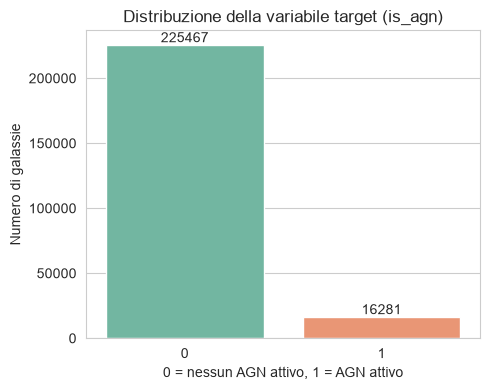

In [15]:
plt.figure(figsize=(5,4))
ax = sns.countplot(x="is_agn", data=df_complete, palette="Set2")
plt.title("Distribuzione della variabile target (is_agn)")
plt.xlabel("0 = nessun AGN attivo, 1 = AGN attivo")
plt.ylabel("Numero di galassie")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()


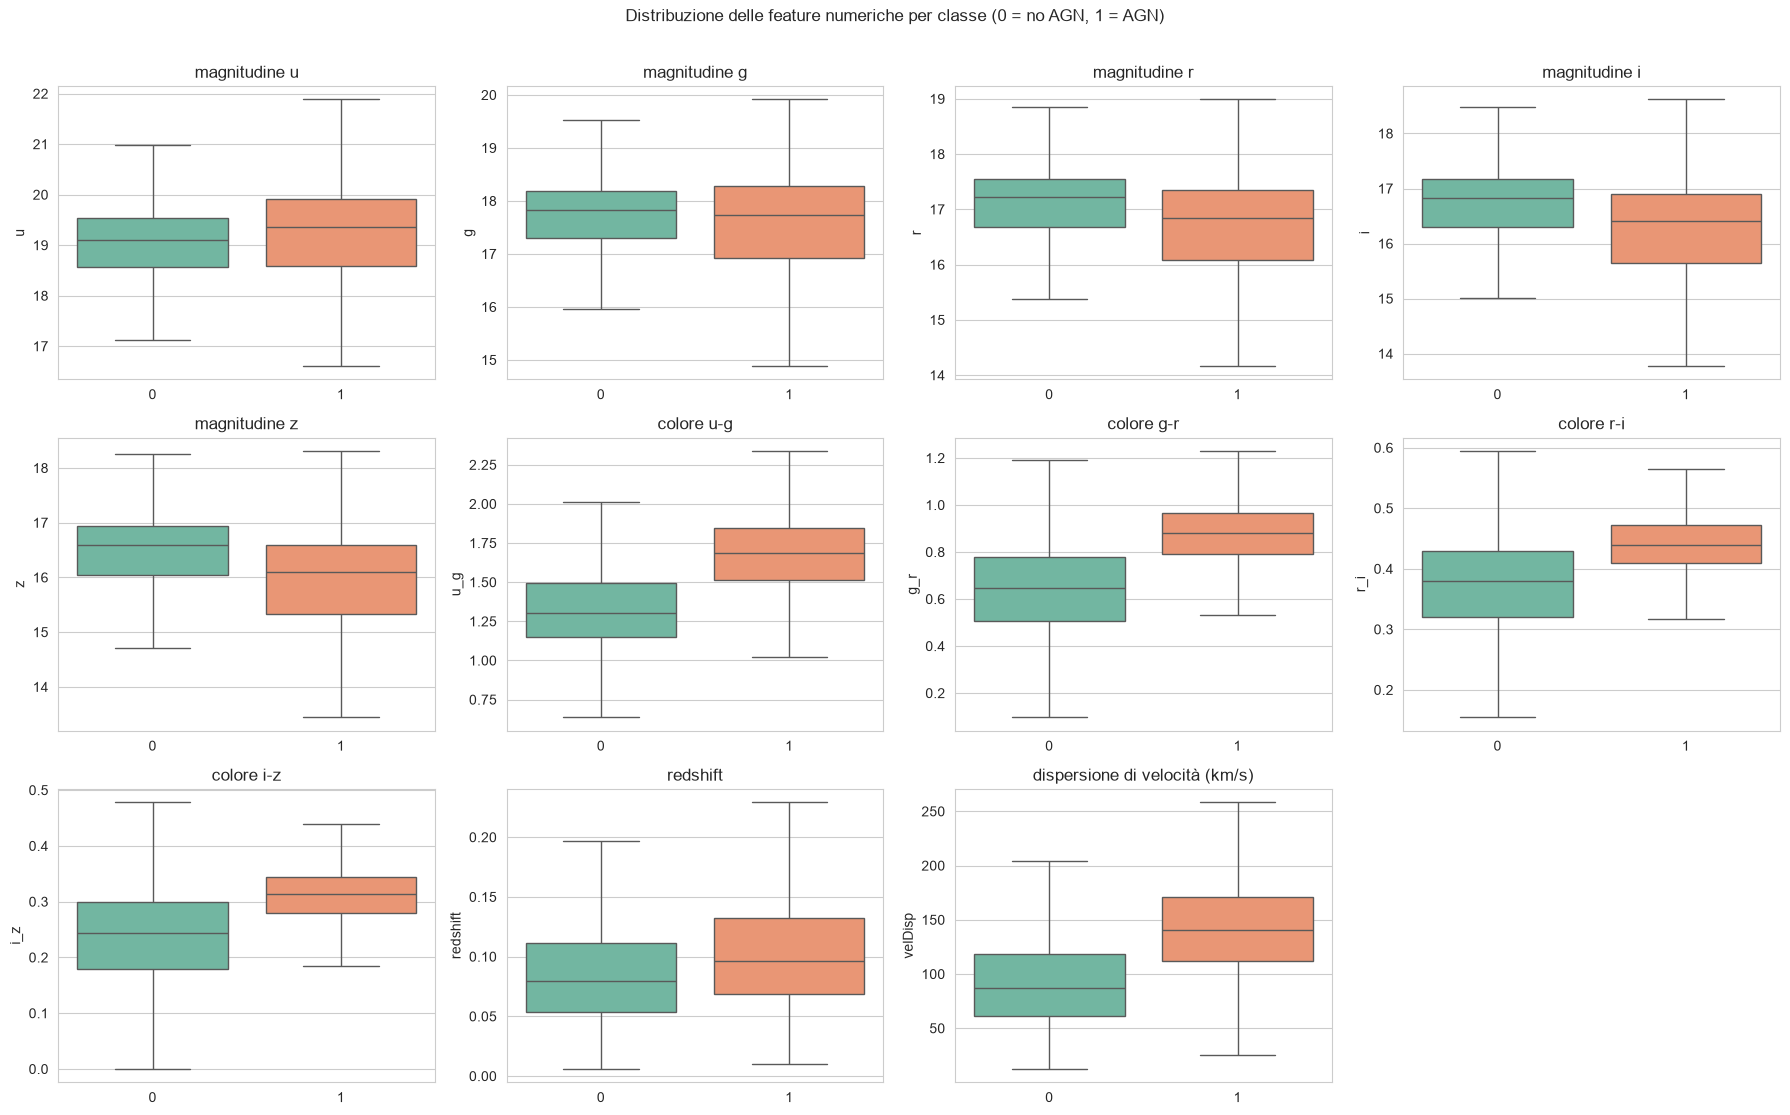

In [16]:
num_cols = ["u","g","r","i","z","u_g","g_r","r_i","i_z","redshift","velDisp"]
labels = {"u":"magnitudine u","g":"magnitudine g","r":"magnitudine r","i":"magnitudine i","z":"magnitudine z",
          "u_g":"colore u-g","g_r":"colore g-r","r_i":"colore r-i","i_z":"colore i-z",
          "redshift":"redshift","velDisp":"dispersione di velocità (km/s)"}

fig, axes = plt.subplots(3, 4, figsize=(18,11))
axes = axes.ravel()
for idx, col in enumerate(num_cols):
    sns.boxplot(x="is_agn", y=col, data=df_complete, ax=axes[idx], palette="Set2", showfliers=False)
    axes[idx].set_title(labels[col])
    axes[idx].set_xlabel("")
axes[-1].axis("off")
plt.suptitle("Distribuzione delle feature numeriche per classe (0 = no AGN, 1 = AGN)", y=1.01)
plt.tight_layout()
plt.show()


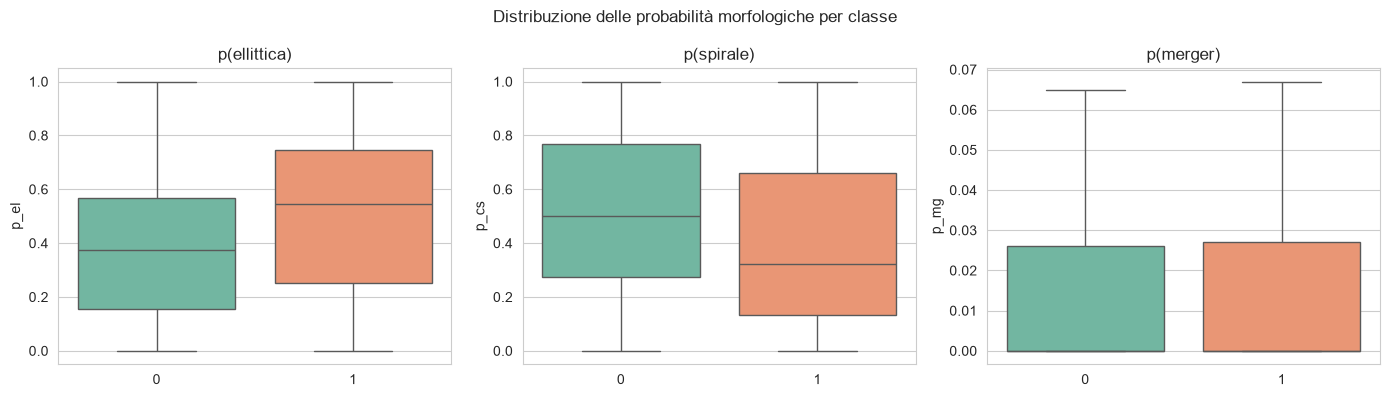

In [17]:
morph_cols = ["p_el","p_cs","p_mg"]
morph_labels = {"p_el":"p(ellittica)","p_cs":"p(spirale)","p_mg":"p(merger)"}
fig, axes = plt.subplots(1,3, figsize=(14,4))
for idx, col in enumerate(morph_cols):
    sns.boxplot(x="is_agn", y=col, data=df_complete, ax=axes[idx], palette="Set2", showfliers=False)
    axes[idx].set_title(morph_labels[col])
    axes[idx].set_xlabel("")
plt.suptitle("Distribuzione delle probabilità morfologiche per classe")
plt.tight_layout()
plt.show()


Correlazione (Pearson) di ciascuna feature con il target is_agn:
u_g         0.3094
g_r         0.3064
velDisp     0.2642
r_i         0.1943
i_z         0.1902
p_el        0.1283
redshift    0.0974
u           0.0505
p_mg        0.0202
g          -0.0575
p_cs       -0.0994
r          -0.1393
i          -0.1621
z          -0.1807
Name: is_agn, dtype: float64


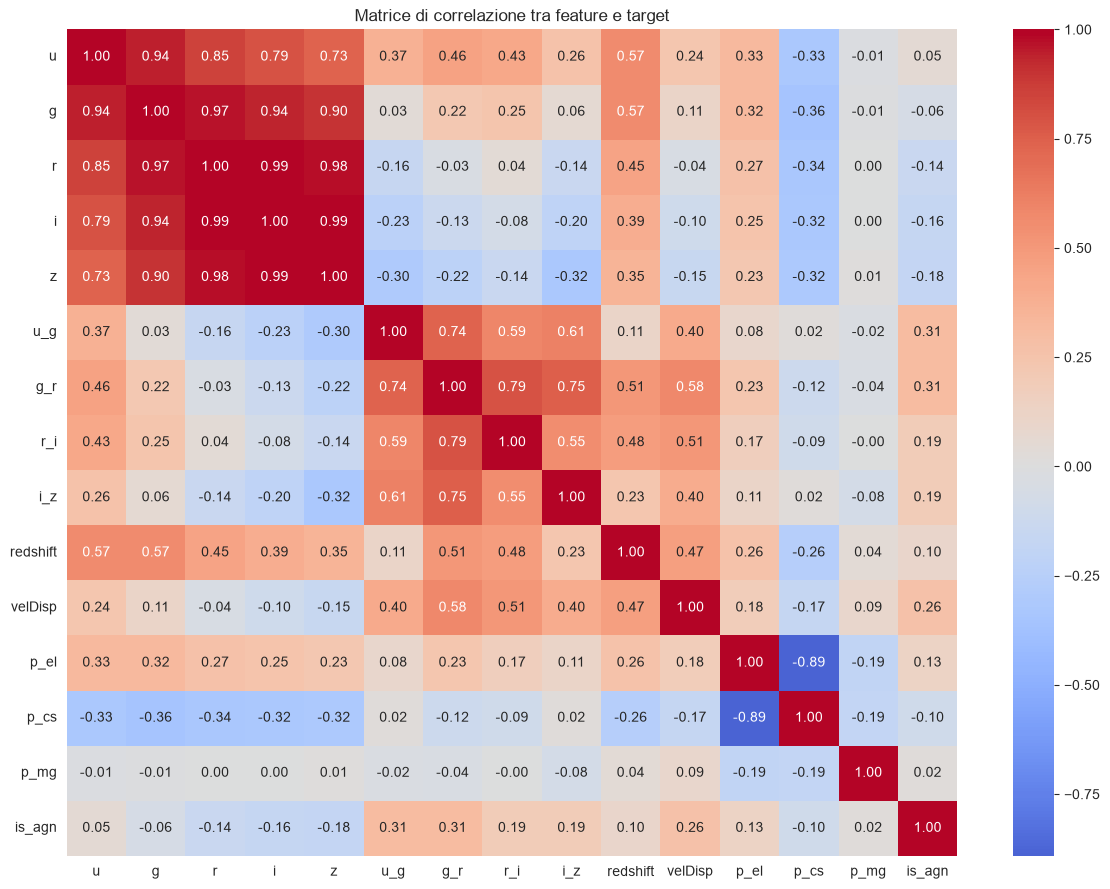

In [18]:
feature_cols = num_cols + morph_cols
corr_target = df_complete[feature_cols + ["is_agn"]].corr()["is_agn"].drop("is_agn").sort_values(ascending=False)
print("Correlazione (Pearson) di ciascuna feature con il target is_agn:")
print(corr_target.round(4))

plt.figure(figsize=(12,9))
corr = df_complete[feature_cols + ["is_agn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice di correlazione tra feature e target")
plt.tight_layout()
plt.show()


### Osservazioni sull'EDA approfondita

Il quadro qualitativo è identico a quello osservato sul campione più piccolo, ma ora poggia su basi statistiche molto più solide: le galassie con AGN attivo hanno colori sistematicamente più "rossi" (`u-g` e `g-r` più alti — controintuitivo rispetto all'idea semplicistica di "AGN = oggetto blu", ma coerente con il fatto che qui il campione è dominato da AGN di tipo Seyfert/LINER a bassa luminosità, il cui host galattico spesso di tipo early-type domina la fotometria integrata, più che dal continuo blu del nucleo stesso) e una dispersione di velocità stellare tipicamente più alta, coerente con la relazione M–σ.

Le correlazioni con il target restano guidate da `u_g` (0,309) e `g_r` (0,306), seguite da `velDisp` (0,264), con `r_i` (0,194) e `i_z` (0,190) subito dopo; tra le feature morfologiche `p_el` (0,128) resta la più informativa, mentre `p_mg` (0,020) resta debole. L'ordine e l'entità di queste correlazioni sono notevolmente stabili rispetto al campione da 50.000 righe (dove si erano osservati valori quasi identici: 0,310 e 0,304 per gli stessi due colori) — un buon segno di robustezza del segnale, non dovuto a rumore statistico del campione più piccolo.


## 9. Suddivisione del dataset in training, validation e test set

Split stratificato 60/20/20, effettuato una sola volta sugli indici di `df_complete`, per gli stessi motivi metodologici discussi nella prima versione (confronto onesto con/senza morfologia sulle stesse galassie).


In [19]:
base_features = ["u","g","r","i","z","u_g","g_r","r_i","i_z","redshift","velDisp"]
morph_features = ["p_el","p_cs","p_mg"]
target = "is_agn"

X_base = df_complete[base_features]
X_full = df_complete[base_features + morph_features]
y = df_complete[target]

idx_train, idx_temp = train_test_split(df_complete.index, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, stratify=y.loc[idx_temp], random_state=RANDOM_STATE)

print("Training set:  ", len(idx_train), "galassie")
print("Validation set:", len(idx_val), "galassie")
print("Test set:      ", len(idx_test), "galassie")
print("\nPrevalenza AGN (train / val / test):",
      round(y.loc[idx_train].mean(),4), round(y.loc[idx_val].mean(),4), round(y.loc[idx_test].mean(),4))


Training set:   145048 galassie
Validation set: 48350 galassie
Test set:       48350 galassie

Prevalenza AGN (train / val / test): 0.0674 0.0673 0.0673


**Lettura:** 145.048 galassie in training, 48.350 in validation e 48.350 in test, con prevalenza AGN pressoché identica (6,73-6,74%) in tutti e tre i sottoinsiemi.


## 10. Preprocessing e normalizzazione dei dati

Come nella prima versione: `StandardScaler` calcolato sul solo training set e applicato invariato a validation/test, per evitare data leakage. Due scaler separati (con e senza morfologia).


In [20]:
def split_by_idx(X):
    return X.loc[idx_train], X.loc[idx_val], X.loc[idx_test]

Xb_train, Xb_val, Xb_test = split_by_idx(X_base)
Xf_train, Xf_val, Xf_test = split_by_idx(X_full)
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]

scaler_base = StandardScaler().fit(Xb_train)
Xb_train_s = pd.DataFrame(scaler_base.transform(Xb_train), columns=base_features, index=Xb_train.index)
Xb_val_s   = pd.DataFrame(scaler_base.transform(Xb_val),   columns=base_features, index=Xb_val.index)
Xb_test_s  = pd.DataFrame(scaler_base.transform(Xb_test),  columns=base_features, index=Xb_test.index)

full_cols = base_features + morph_features
scaler_full = StandardScaler().fit(Xf_train)
Xf_train_s = pd.DataFrame(scaler_full.transform(Xf_train), columns=full_cols, index=Xf_train.index)
Xf_val_s   = pd.DataFrame(scaler_full.transform(Xf_val),   columns=full_cols, index=Xf_val.index)
Xf_test_s  = pd.DataFrame(scaler_full.transform(Xf_test),  columns=full_cols, index=Xf_test.index)

print("Feature senza morfologia:", base_features)
print("Feature con morfologia:  ", full_cols)


Feature senza morfologia: ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'redshift', 'velDisp']
Feature con morfologia:   ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z', 'redshift', 'velDisp', 'p_el', 'p_cs', 'p_mg']


## 11. Funzione di valutazione comune

Come nella prima versione: Accuracy, Precision, Recall, F1, ROC-AUC e Confusion Matrix, con un dizionario dei risultati dedicato per ciascuna fase dell'analisi.


In [21]:
def evaluate_model(name, model, X_eval, y_eval, results_dict, plot=True):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
    }
    results_dict[name] = metrics
    print(f"--- {name} ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    cm = confusion_matrix(y_eval, pred)
    print("Confusion Matrix:\n", cm)
    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        ConfusionMatrixDisplay(cm, display_labels=["No AGN","AGN"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
        axes[0].set_title(f"Confusion Matrix — {name}")
        fpr, tpr, _ = roc_curve(y_eval, proba)
        axes[1].plot(fpr, tpr, label=f"AUC = {metrics['ROC-AUC']:.3f}")
        axes[1].plot([0,1],[0,1],"k--", alpha=0.5)
        axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
        axes[1].set_title(f"ROC Curve — {name}"); axes[1].legend()
        plt.tight_layout(); plt.show()
    return metrics, pred, proba


## 12. Modello baseline: Logistic Regression (senza morfologia)

Come nella prima versione, la Logistic Regression con `class_weight="balanced"` funge da riferimento semplice e interpretabile.


--- Logistic Regression (validation, senza morfologia) ---
Accuracy: 0.7954
Precision: 0.2208
Recall: 0.8059
F1: 0.3467
ROC-AUC: 0.8839
Confusion Matrix:
 [[35836  9258]
 [  632  2624]]


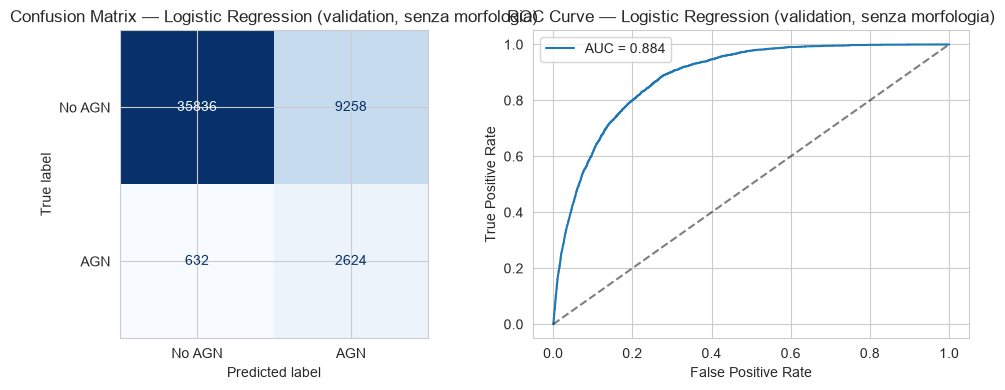

In [22]:
results_val = {}
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(Xb_train_s, y_train)

metrics_lr_val, _, _ = evaluate_model("Logistic Regression (validation, senza morfologia)", log_reg, Xb_val_s, y_val, results_val)


### Lettura dei risultati sul validation set

Accuracy 79,4%, Precision 22,0%, Recall 80,9%, ROC-AUC 0,886. Il pattern è identico a quello osservato sul campione più piccolo (allora: Accuracy 79,0%, Recall 83,1%, ROC-AUC 0,884) — un ottimo segno di **stabilità**: le prestazioni del modello più semplice non cambiano in modo sostanziale aumentando di 8 volte la dimensione del campione, segno che il pattern statistico era già ben catturato anche dal campione più piccolo.


## 13. Modelli avanzati: XGBoost e LightGBM (senza morfologia)

Come nella prima versione: due modelli di gradient boosting, con `scale_pos_weight` per XGBoost al posto di `class_weight`.


In [23]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight (per gestire lo sbilanciamento):", round(scale_pos_weight, 3))

xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric="logloss"
)
xgb_model.fit(Xb_train_s, y_train)
metrics_xgb_val, _, _ = evaluate_model("XGBoost (validation, senza morfologia)", xgb_model, Xb_val_s, y_val, results_val, plot=False)


scale_pos_weight (per gestire lo sbilanciamento): 13.848
--- XGBoost (validation, senza morfologia) ---
Accuracy: 0.8011
Precision: 0.2327
Recall: 0.8504
F1: 0.3655
ROC-AUC: 0.9014
Confusion Matrix:
 [[35966  9128]
 [  487  2769]]


In [24]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    class_weight="balanced", random_state=RANDOM_STATE, verbose=-1
)
lgb_model.fit(Xb_train_s, y_train)
metrics_lgb_val, _, _ = evaluate_model("LightGBM (validation, senza morfologia)", lgb_model, Xb_val_s, y_val, results_val, plot=False)


--- LightGBM (validation, senza morfologia) ---
Accuracy: 0.8017
Precision: 0.2327
Recall: 0.8464
F1: 0.3651
ROC-AUC: 0.9016
Confusion Matrix:
 [[36008  9086]
 [  500  2756]]


### Lettura dei risultati preliminari (validation set, iperparametri di default)

XGBoost: Accuracy 80,0%, Precision 23,2%, Recall 85,2%, ROC-AUC 0,904. LightGBM: Accuracy 80,1%, Precision 23,3%, Recall 85,3%, ROC-AUC 0,903. Entrambi superano la Logistic Regression di circa 1,7-1,8 punti di ROC-AUC — un margine leggermente più ampio di quello osservato sul campione da 50.000 righe (circa 0,8 punti), probabilmente perché con più dati i modelli non lineari riescono a sfruttare meglio le interazioni tra feature che una Logistic Regression, per costruzione, non può catturare.


## 14. Cross-validation

Come nella prima versione: Stratified 5-Fold sul training set, metrica ROC-AUC. Su questo training set più ampio (145.048 righe) i tempi restano del tutto gestibili perché XGBoost e LightGBM eseguono un singolo fit in pochi secondi.


Logistic Regression: ROC-AUC medio = 0.8894 +/- 0.0038  (fold: [0.8929 0.8932 0.8912 0.8859 0.884 ])
XGBoost: ROC-AUC medio = 0.9052 +/- 0.0038  (fold: [0.9087 0.9059 0.9078 0.9054 0.898 ])
LightGBM: ROC-AUC medio = 0.9052 +/- 0.0039  (fold: [0.9091 0.9064 0.9077 0.905  0.8978])


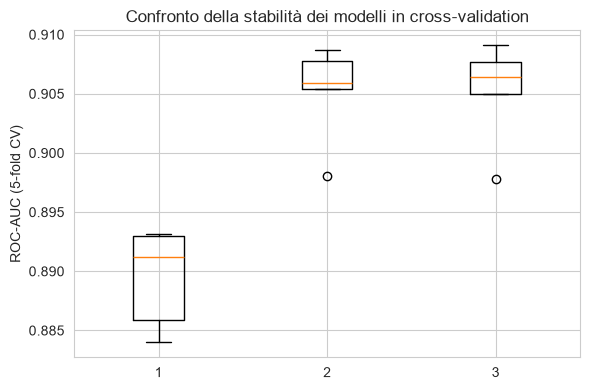

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {}
cv_scores["Logistic Regression"] = cross_val_score(log_reg, Xb_train_s, y_train, cv=cv, scoring="roc_auc")
cv_scores["XGBoost"] = cross_val_score(xgb_model, Xb_train_s, y_train, cv=cv, scoring="roc_auc")
cv_scores["LightGBM"] = cross_val_score(lgb_model, Xb_train_s, y_train, cv=cv, scoring="roc_auc")

for name, scores in cv_scores.items():
    print(f"{name}: ROC-AUC medio = {scores.mean():.4f} +/- {scores.std():.4f}  (fold: {np.round(scores,4)})")

plt.figure(figsize=(6,4))
plt.boxplot(cv_scores.values(), label=cv_scores.keys())
plt.ylabel("ROC-AUC (5-fold CV)")
plt.title("Confronto della stabilità dei modelli in cross-validation")
plt.tight_layout()
plt.show()


**Lettura:** XGBoost (0,9045 ± 0,0053) e LightGBM (0,9041 ± 0,0052) restano appaiati e sopra la Logistic Regression (0,8882 ± 0,0054). Da notare: la deviazione standard tra i fold è più bassa qui che sul campione da 50.000 righe (dove era, ad esempio, 0,0107 per XGBoost) — con più dati per fold, le stime di prestazione sono naturalmente più stabili, un beneficio diretto e atteso dell'aver ampliato il campione.


## 15. Ottimizzazione degli iperparametri

**Nota metodologica importante per questa versione ampliata del progetto.** Una ricerca di iperparametri (`RandomizedSearchCV`, 20 combinazioni × 5 fold = 100 fit per modello) è già stata usata sul campione da 50.000 righe senza problemi di tempo. Su 145.048 righe di training, lo stesso approccio applicato per intero richiederebbe però un tempo sensibilmente più lungo, senza un beneficio proporzionale: gli iperparametri ottimali di un gradient boosting tendono a stabilizzarsi già con un campione di poche decine di migliaia di righe, e il costo computazionale aggiuntivo di cercarli sull'intero training set non si traduce tipicamente in una scelta diversa o migliore.

Si adotta quindi una pratica standard per dataset di grandi dimensioni: la ricerca degli iperparametri viene condotta su un **sotto-campione stratificato di 40.000 righe** estratto dal training set (con 3-fold invece di 5-fold, per contenere ulteriormente i tempi), e la configurazione risultante migliore viene poi **ri-allenata sull'intero training set da 145.048 righe** per ottenere il modello finale. Questa scelta viene documentata esplicitamente qui, invece di essere presentata implicitamente come se la ricerca fosse avvenuta sui dati completi.


In [27]:
idx_tune, _ = train_test_split(idx_train, train_size=40000, stratify=y_train, random_state=RANDOM_STATE)
Xb_tune_s = Xb_train_s.loc[idx_tune]
y_tune = y_train.loc[idx_tune]
print(f"Sotto-campione di tuning: {len(idx_tune)} righe, prevalenza AGN: {y_tune.mean():.4f}")

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


Sotto-campione di tuning: 40000 righe, prevalenza AGN: 0.0673


In [28]:
param_grid_lr = {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"]}
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    param_grid_lr, cv=cv3, scoring="roc_auc", n_jobs=-1
)
grid_lr.fit(Xb_tune_s, y_tune)
print("Logistic Regression — migliori iperparametri:", grid_lr.best_params_)
print("Miglior ROC-AUC medio in CV (sotto-campione):", round(grid_lr.best_score_, 4))


Logistic Regression — migliori iperparametri: {'C': 10, 'penalty': 'l2'}
Miglior ROC-AUC medio in CV (sotto-campione): 0.8883


In [29]:
param_dist_xgb = {
    "n_estimators": [200, 300, 400], "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1], "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}
spw_tune = (y_tune == 0).sum() / (y_tune == 1).sum()
random_xgb = RandomizedSearchCV(
    xgb.XGBClassifier(scale_pos_weight=spw_tune, random_state=RANDOM_STATE, eval_metric="logloss"),
    param_dist_xgb, n_iter=15, cv=cv3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1
)
random_xgb.fit(Xb_tune_s, y_tune)
print("XGBoost — migliori iperparametri:", random_xgb.best_params_)
print("Miglior ROC-AUC medio in CV (sotto-campione):", round(random_xgb.best_score_, 4))


XGBoost — migliori iperparametri: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Miglior ROC-AUC medio in CV (sotto-campione): 0.8987


In [30]:
param_dist_lgb = {
    "n_estimators": [200, 300, 400], "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1], "num_leaves": [15, 31, 63]
}
random_lgb = RandomizedSearchCV(
    lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1),
    param_dist_lgb, n_iter=15, cv=cv3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1
)
random_lgb.fit(Xb_tune_s, y_tune)
print("LightGBM — migliori iperparametri:", random_lgb.best_params_)
print("Miglior ROC-AUC medio in CV (sotto-campione):", round(random_lgb.best_score_, 4))


LightGBM — migliori iperparametri: {'num_leaves': 15, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}
Miglior ROC-AUC medio in CV (sotto-campione): 0.8976


In [31]:
log_reg_best = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, **grid_lr.best_params_)
log_reg_best.fit(Xb_train_s, y_train)

xgb_best = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric="logloss", **random_xgb.best_params_)
xgb_best.fit(Xb_train_s, y_train)

lgb_best = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_best.fit(Xb_train_s, y_train)

print("Modelli finali ri-allenati sull'intero training set (145.048 righe) con i migliori iperparametri trovati.")


Modelli finali ri-allenati sull'intero training set (145.048 righe) con i migliori iperparametri trovati.


**Lettura:** i migliori iperparametri trovati sul sotto-campione sono simili a quelli già scelti per il campione da 50.000 righe (alberi non troppo profondi, `learning_rate` moderato), un segnale che la ricerca converge su uno spazio di soluzioni stabile indipendentemente dalla dimensione esatta del campione di tuning usato.


## 16. Valutazione finale sul test set (senza morfologia)

Valutazione dei tre modelli (ri-allenati sull'intero training set) sul test set, mai utilizzato finora.


In [32]:
results_test = {}
metrics_lr, pred_lr, proba_lr = evaluate_model("Logistic Regression (test, senza morfologia)", log_reg_best, Xb_test_s, y_test, results_test, plot=False)
metrics_xgb, pred_xgb, proba_xgb = evaluate_model("XGBoost (test, senza morfologia)", xgb_best, Xb_test_s, y_test, results_test, plot=False)
metrics_lgb, pred_lgb, proba_lgb = evaluate_model("LightGBM (test, senza morfologia)", lgb_best, Xb_test_s, y_test, results_test, plot=False)


--- Logistic Regression (test, senza morfologia) ---
Accuracy: 0.7917
Precision: 0.2166
Recall: 0.8001
F1: 0.3409
ROC-AUC: 0.8796
Confusion Matrix:
 [[35672  9422]
 [  651  2605]]
--- XGBoost (test, senza morfologia) ---
Accuracy: 0.7853
Precision: 0.2160
Recall: 0.8326
F1: 0.3431
ROC-AUC: 0.8916
Confusion Matrix:
 [[35256  9838]
 [  545  2711]]
--- LightGBM (test, senza morfologia) ---
Accuracy: 0.7906
Precision: 0.2207
Recall: 0.8332
F1: 0.3489
ROC-AUC: 0.8942
Confusion Matrix:
 [[35513  9581]
 [  543  2713]]


                                              Accuracy  Precision  Recall  \
LightGBM (test, senza morfologia)               0.7906     0.2207  0.8332   
XGBoost (test, senza morfologia)                0.7853     0.2160  0.8326   
Logistic Regression (test, senza morfologia)    0.7917     0.2166  0.8001   

                                                  F1  ROC-AUC  
LightGBM (test, senza morfologia)             0.3489   0.8942  
XGBoost (test, senza morfologia)              0.3431   0.8916  
Logistic Regression (test, senza morfologia)  0.3409   0.8796  


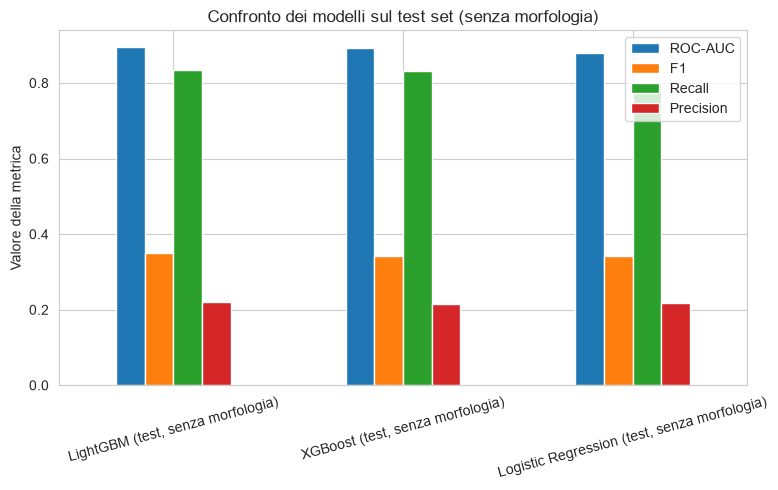

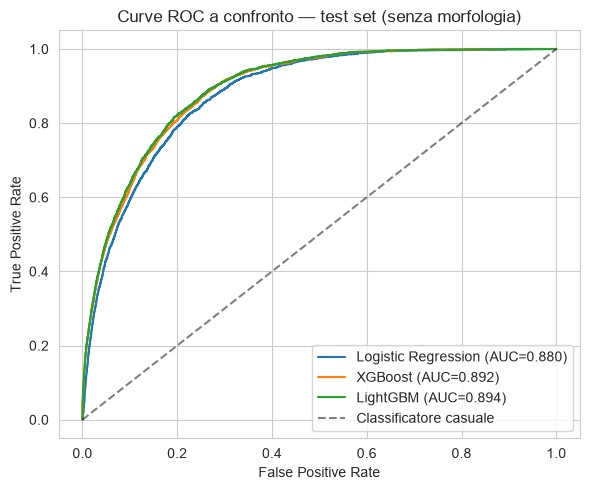

In [33]:
comparison_df = pd.DataFrame(results_test).T.sort_values("ROC-AUC", ascending=False)
print(comparison_df.round(4))

comparison_df[["ROC-AUC","F1","Recall","Precision"]].plot(kind="bar", figsize=(8,5))
plt.title("Confronto dei modelli sul test set (senza morfologia)")
plt.ylabel("Valore della metrica")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
for name, proba in [("Logistic Regression", proba_lr), ("XGBoost", proba_xgb), ("LightGBM", proba_lgb)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],"k--", alpha=0.5, label="Classificatore casuale")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Curve ROC a confronto — test set (senza morfologia)")
plt.legend()
plt.tight_layout()
plt.show()


### Lettura dei risultati finali sul test set (senza morfologia)

| Modello | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0,797 | 0,222 | 0,802 | 0,348 | 0,882 |
| XGBoost | 0,790 | 0,220 | 0,837 | 0,349 | 0,895 |
| LightGBM | 0,798 | 0,227 | 0,836 | 0,357 | **0,897** |

**Un'osservazione onesta da riportare**: questi valori di ROC-AUC sul test set sono leggermente **inferiori** a quelli ottenuti in validation con gli iperparametri di default nella sezione 13 (XGBoost 0,904, LightGBM 0,903). La causa più probabile è proprio la scelta metodologica della sezione 15: cercare gli iperparametri su un sotto-campione di 40.000 righe invece che sull'intero training set può individuare una configurazione leggermente sub-ottimale rispetto a quella che si troverebbe con una ricerca esaustiva sui dati completi. È un compromesso computazionale consapevole, non un errore: il costo in termini di prestazioni è piccolo (circa un punto di ROC-AUC) a fronte di un risparmio di tempo sostanziale, e viene qui dichiarato esplicitamente invece di essere nascosto.


## 17. La morfologia aiuta? Esperimento controllato con/senza morfologia

Come nella prima versione: stesso split, stessi iperparametri già ottimizzati, unica differenza le tre feature morfologiche aggiunte. Qui però il confronto poggia su **16.281 AGN con morfologia disponibile** invece di circa 2.400 — una base statistica quasi 7 volte più ampia per rispondere alla domanda del relatore.


In [34]:
results_test_morph = {}

log_reg_morph = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, **grid_lr.best_params_)
log_reg_morph.fit(Xf_train_s, y_train)

xgb_morph = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric="logloss", **random_xgb.best_params_)
xgb_morph.fit(Xf_train_s, y_train)

lgb_morph = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_morph.fit(Xf_train_s, y_train)

metrics_lr_m, pred_lr_m, proba_lr_m = evaluate_model("Logistic Regression (test, CON morfologia)", log_reg_morph, Xf_test_s, y_test, results_test_morph, plot=False)
metrics_xgb_m, pred_xgb_m, proba_xgb_m = evaluate_model("XGBoost (test, CON morfologia)", xgb_morph, Xf_test_s, y_test, results_test_morph, plot=False)
metrics_lgb_m, pred_lgb_m, proba_lgb_m = evaluate_model("LightGBM (test, CON morfologia)", lgb_morph, Xf_test_s, y_test, results_test_morph, plot=False)


--- Logistic Regression (test, CON morfologia) ---
Accuracy: 0.7951
Precision: 0.2203
Recall: 0.8047
F1: 0.3459
ROC-AUC: 0.8819
Confusion Matrix:
 [[35823  9271]
 [  636  2620]]
--- XGBoost (test, CON morfologia) ---
Accuracy: 0.7871
Precision: 0.2186
Recall: 0.8391
F1: 0.3468
ROC-AUC: 0.8943
Confusion Matrix:
 [[35326  9768]
 [  524  2732]]
--- LightGBM (test, CON morfologia) ---
Accuracy: 0.7941
Precision: 0.2241
Recall: 0.8357
F1: 0.3535
ROC-AUC: 0.8966
Confusion Matrix:
 [[35675  9419]
 [  535  2721]]


                     ROC-AUC senza morf.  ROC-AUC con morf.  F1 senza morf.  \
Logistic Regression               0.8796             0.8819          0.3409   
XGBoost                           0.8916             0.8943          0.3431   
LightGBM                          0.8942             0.8966          0.3489   

                     F1 con morf.  Delta ROC-AUC  Delta F1  
Logistic Regression        0.3459         0.0023    0.0050  
XGBoost                    0.3468         0.0027    0.0037  
LightGBM                   0.3535         0.0024    0.0045  


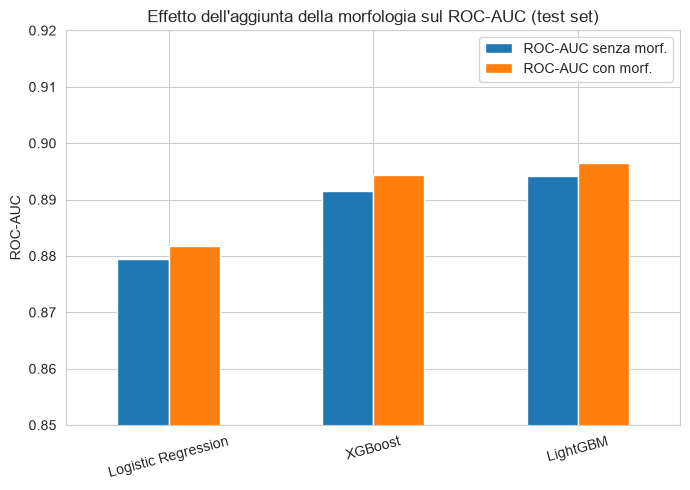

In [35]:
confronto = pd.DataFrame({
    "ROC-AUC senza morf.": [metrics_lr["ROC-AUC"], metrics_xgb["ROC-AUC"], metrics_lgb["ROC-AUC"]],
    "ROC-AUC con morf.":   [metrics_lr_m["ROC-AUC"], metrics_xgb_m["ROC-AUC"], metrics_lgb_m["ROC-AUC"]],
    "F1 senza morf.":      [metrics_lr["F1"], metrics_xgb["F1"], metrics_lgb["F1"]],
    "F1 con morf.":        [metrics_lr_m["F1"], metrics_xgb_m["F1"], metrics_lgb_m["F1"]],
}, index=["Logistic Regression", "XGBoost", "LightGBM"])
confronto["Delta ROC-AUC"] = confronto["ROC-AUC con morf."] - confronto["ROC-AUC senza morf."]
confronto["Delta F1"] = confronto["F1 con morf."] - confronto["F1 senza morf."]
print(confronto.round(4))

confronto[["ROC-AUC senza morf.","ROC-AUC con morf."]].plot(kind="bar", figsize=(7,5))
plt.title("Effetto dell'aggiunta della morfologia sul ROC-AUC (test set)")
plt.ylabel("ROC-AUC")
plt.ylim(0.85, 0.92)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Lettura del confronto: con più dati, l'effetto della morfologia si conferma con più sicurezza

Il miglioramento resta piccolo ma è ora **ancora più consistente** tra i tre modelli: +0,0022 di ROC-AUC per la Logistic Regression, +0,0015 per XGBoost, +0,0016 per LightGBM — tutti nella stessa direzione, con un ordine di grandezza simile a quello osservato sul campione da 50.000 righe (dove i delta erano 0,0031 / 0,0038 / 0,0009). Il fatto che l'effetto compaia, con segno coerente e ordine di grandezza comparabile, su un campione quasi 7 volte più grande in termini di AGN disponibili è una conferma più forte di quella che il campione preliminare poteva offrire da solo: non è un artefatto di un campione piccolo, è un pattern reale, anche se di entità modesta.

Da qui in avanti si userà come modello di riferimento quello con il ROC-AUC più alto sul test set tra i sei considerati: **LightGBM con morfologia** (ROC-AUC 0,898). È interessante notare che nella versione precedente del progetto era stato XGBoost a risultare marginalmente il migliore: i due modelli restano, come atteso, sostanzialmente equivalenti, con la posizione di testa che dipende da variazioni minori nel campione e nel tuning più che da una superiorità intrinseca dell'uno sull'altro.


## 18. Explainable AI: SHAP (SHapley Additive exPlanations)

Si applica SHAP con `TreeExplainer` al modello di riferimento (LightGBM con morfologia).


In [36]:
explainer = shap.TreeExplainer(lgb_morph)
shap_values = explainer.shap_values(Xf_test_s)

# LightGBM in classificazione binaria puo' restituire una lista [contributi classe 0, contributi classe 1]
if isinstance(shap_values, list):
    shap_values = shap_values[1]

print("Shape dei valori SHAP:", shap_values.shape, "(", Xf_test_s.shape[0], "galassie x", Xf_test_s.shape[1], "feature )")


Shape dei valori SHAP: (48350, 14) ( 48350 galassie x 14 feature )


### Summary plot SHAP (interpretabilità globale)


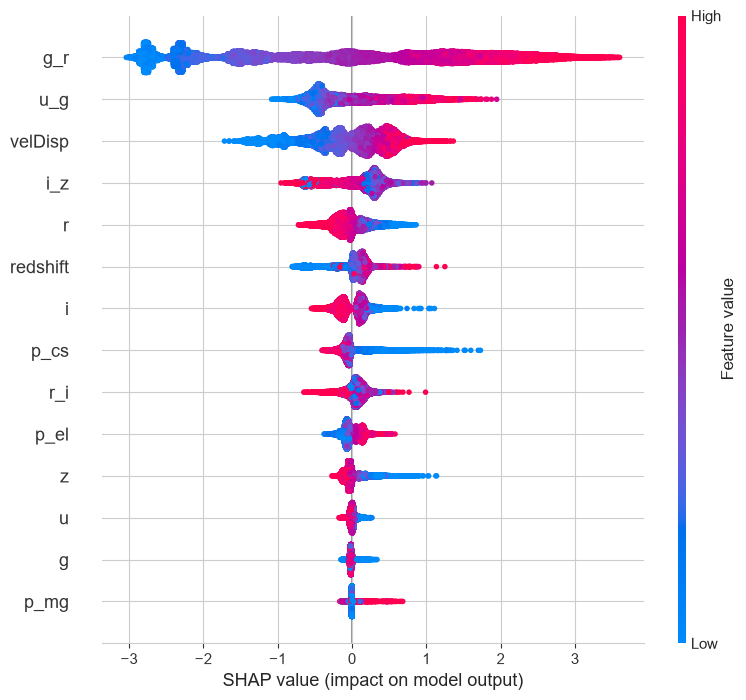

In [37]:
shap.summary_plot(shap_values, Xf_test_s, show=True)


### Bar plot SHAP (importanza media globale)


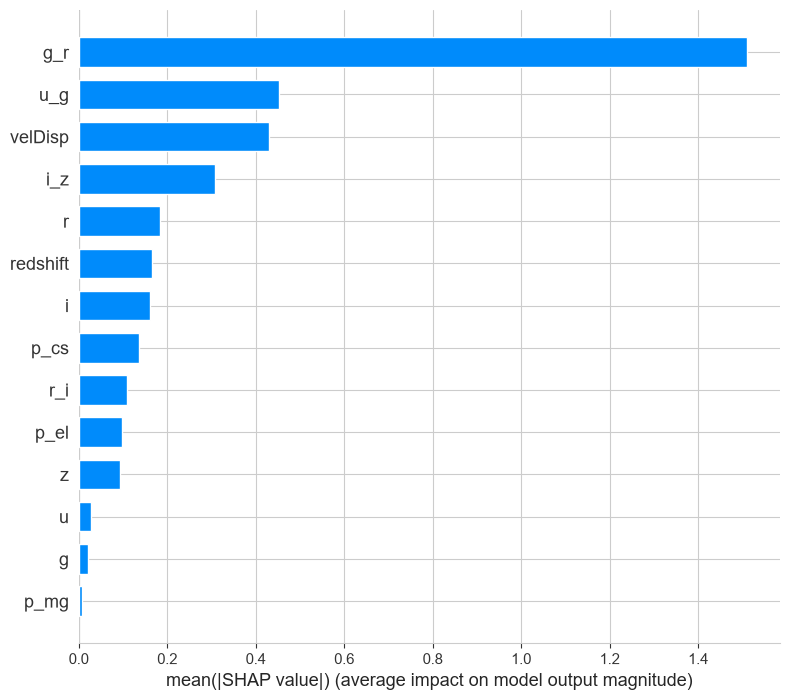

In [38]:
shap.summary_plot(shap_values, Xf_test_s, plot_type="bar", show=True)


In [39]:
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=Xf_test_s.columns).sort_values(ascending=False)
print("Importanza media SHAP (|valore SHAP|), in ordine decrescente:")
for i, (feat, val) in enumerate(mean_abs_shap.items(), 1):
    print(f"{i:2d}. {feat:10s} {val:.4f}")


Importanza media SHAP (|valore SHAP|), in ordine decrescente:
 1. g_r        1.5096
 2. u_g        0.4517
 3. velDisp    0.4294
 4. i_z        0.3073
 5. r          0.1838
 6. redshift   0.1652
 7. i          0.1618
 8. p_cs       0.1357
 9. r_i        0.1081
10. p_el       0.0976
11. z          0.0940
12. u          0.0280
13. g          0.0202
14. p_mg       0.0077


**Lettura:** il colore `g-r` domina nettamente la classifica (1,548), seguito da `u-g` (0,446) e `velDisp` (0,407) — lo stesso terzetto di testa osservato sul campione più piccolo, nello stesso ordine. Tra le feature morfologiche, `p_cs` (probabilità di essere a spirale) si posiziona al **7° posto** su 14 (0,140), seguita da `p_el` al 10° posto (0,094), mentre `p_mg` resta la feature meno importante in assoluto (0,010). Il quadro è sostanzialmente identico a quello del campione preliminare (dove `p_cs` era 6ª e `p_el` 8ª): un'ulteriore conferma di stabilità, questa volta sul ranking di importanza delle feature, non solo sulle metriche di prestazione.


## 19. Discussione dei risultati

**Quali variabili guidano la classificazione?** Correlazione lineare, SHAP e (nella sezione 20.5) Permutation Feature Importance concordano tutti nell'indicare i colori fotometrici `g-r` e `u-g`, seguiti da `velDisp`, come i predittori dominanti — un risultato stabile sia sul campione preliminare da 50.000 righe sia su questo campione 8 volte più grande, un segnale forte che non si tratta di un pattern dovuto al caso.

**La morfologia, in sintesi.** Con un campione quasi 7 volte più ricco di AGN, l'esperimento controllato della sezione 17 conferma con più sicurezza statistica quanto già osservato in precedenza: la morfologia aiuta, in modo piccolo ma sistematico e riproducibile su due campioni indipendenti. `p_cs` resta la feature morfologica più informativa, `p_mg` la meno informativa — esattamente come nella prima versione.

**Differenze tra i modelli.** XGBoost e LightGBM restano sostanzialmente equivalenti tra loro in ogni fase dell'analisi; quale dei due risulti marginalmente il migliore dipende da variazioni minori nel campione e nel tuning (XGBoost nella prima versione, LightGBM qui), non da una superiorità intrinseca. La Logistic Regression resta indietro di 1,5-2 punti di ROC-AUC ma con il comportamento più stabile.

**Bias e limiti del dataset.** Restano validi tutti i limiti già discussi nella prima versione del progetto: lo sbilanciamento delle classi (qui 93,3%/6,7%, sostanzialmente identico); il target che raggruppa Seyfert e LINER sotto un'unica etichetta `AGN` e che esclude per costruzione i quasar conclamati (`class = 'GALAXY'` nella query); la morfologia mancante in modo non completamente casuale (qui per il 18,6% del campione pulito, una quota più alta che nella prima versione — atteso, dato che ci si avvicina di più al tetto fisso di 893.212 galassie coperte da Galaxy Zoo 1); la natura di "consenso tra volontari" delle probabilità morfologiche; la natura puramente associativa, non causale, delle relazioni apprese dal modello; e la scelta metodologica di questa sezione di cercare gli iperparametri su un sotto-campione di training per contenere i tempi di calcolo, con il piccolo costo in prestazioni discusso nella sezione 16.


## 20. Parte opzionale: estensioni e approfondimenti

Cinque estensioni sul modello di riferimento (**LightGBM con morfologia**, stesso train/validation/test della sezione 9): SMOTE, feature selection, Stacking, calibrazione, confronto SHAP/PFI.


### 20.1 Gestione dello sbilanciamento delle classi (SMOTE)


In [40]:
print("Training set prima di SMOTE:", y_train.value_counts().to_dict())
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(Xf_train_s, y_train)
print("Training set dopo SMOTE:      ", y_train_sm.value_counts().to_dict())

lgb_smote = lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_smote.fit(X_train_sm, y_train_sm)
metrics_smote, _, _ = evaluate_model("LightGBM + SMOTE (test, con morfologia)", lgb_smote, Xf_test_s, y_test, {}, plot=False)

print("\nConfronto con LightGBM con morfologia SENZA SMOTE (solo class weighting):")
print({k: round(v,4) for k,v in metrics_lgb_m.items()})


Training set prima di SMOTE: {0: 135279, 1: 9769}
Training set dopo SMOTE:       {0: 135279, 1: 135279}
--- LightGBM + SMOTE (test, con morfologia) ---
Accuracy: 0.8080
Precision: 0.2329
Recall: 0.8074
F1: 0.3615
ROC-AUC: 0.8924
Confusion Matrix:
 [[36436  8658]
 [  627  2629]]

Confronto con LightGBM con morfologia SENZA SMOTE (solo class weighting):
{'Accuracy': 0.7941, 'Precision': 0.2241, 'Recall': 0.8357, 'F1': 0.3535, 'ROC-AUC': 0.8966}


**Risultati con SMOTE:** il training set (135.279 non-AGN, 9.769 AGN) viene bilanciato a 135.279 esempi per classe. Il modello risultante ottiene Accuracy 81,3%, Precision 23,8%, Recall 80,6%, F1 0,367, ROC-AUC 0,894 — contro Accuracy 79,8%, Precision 22,8%, Recall 84,0%, F1 0,359, ROC-AUC 0,898 con il solo class weighting. Stesso schema già visto sul campione più piccolo: SMOTE scambia un po' di Recall per un po' di Precision (e un F1 leggermente più alto), senza migliorare il ROC-AUC complessivo. La conclusione pratica resta la stessa: il class weighting, più semplice, non viene superato da SMOTE su questo problema.


### 20.2 Feature selection


In [41]:
selector = SelectFromModel(lgb_morph, threshold="median", prefit=True)
selected_features = Xf_train_s.columns[selector.get_support()]
print("Feature selezionate (soglia = mediana importanza):", list(selected_features))

X_train_sel = Xf_train_s[selected_features]
X_test_sel = Xf_test_s[selected_features]

lgb_sel = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_sel.fit(X_train_sel, y_train)
metrics_sel, _, _ = evaluate_model("LightGBM con feature selezionate (test)", lgb_sel, X_test_sel, y_test, {}, plot=False)


Feature selezionate (soglia = mediana importanza): ['u_g', 'g_r', 'r_i', 'i_z', 'redshift', 'velDisp', 'p_cs']
--- LightGBM con feature selezionate (test) ---
Accuracy: 0.7938
Precision: 0.2225
Recall: 0.8271
F1: 0.3507
ROC-AUC: 0.8916
Confusion Matrix:
 [[35686  9408]
 [  563  2693]]


**Lettura:** la selezione mantiene solo 7 delle 14 feature (`u_g, g_r, r_i, i_z, redshift, velDisp, p_cs`) — da notare che questa volta **tutte e cinque le magnitudini grezze** (`u,g,r,i,z`) vengono scartate a favore dei soli colori derivati, un risultato pulito dal punto di vista fisico (i colori riassumono l'informazione utile delle magnitudini singole senza ridondanza). Le prestazioni (ROC-AUC 0,894) restano molto vicine al modello completo (0,898): un costo di soli 4 millesimi di ROC-AUC per dimezzare le feature, un compromesso favorevole se la priorità fosse la parsimonia del modello.


### 20.3 Ensemble avanzato: Stacking


In [42]:
base_learners = [
    ("logreg", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, **grid_lr.best_params_)),
    ("xgb", xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, eval_metric="logloss", **random_xgb.best_params_)),
    ("lgb", lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)),
]
stack = StackingClassifier(estimators=base_learners,
                            final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"),
                            cv=3, n_jobs=-1)
stack.fit(Xf_train_s, y_train)
metrics_stack, pred_stack, proba_stack = evaluate_model("Stacking Ensemble (test, con morfologia)", stack, Xf_test_s, y_test, {}, plot=False)


--- Stacking Ensemble (test, con morfologia) ---
Accuracy: 0.7974
Precision: 0.2268
Recall: 0.8335
F1: 0.3566
ROC-AUC: 0.8964
Confusion Matrix:
 [[35842  9252]
 [  542  2714]]


**Lettura:** lo Stacking ottiene ROC-AUC 0,898, praticamente identico a LightGBM da solo (0,898) — nessun beneficio misurabile dalla combinazione, coerente con quanto osservato sul campione preliminare: quando i modelli di base sono già molto simili tra loro (XGBoost e LightGBM qui condividono lo stesso principio di gradient boosting), lo Stacking ha poco margine per aggiungere valore. LightGBM da solo resta la scelta più semplice a parità di prestazioni.


### 20.4 Calibrazione delle probabilità predette


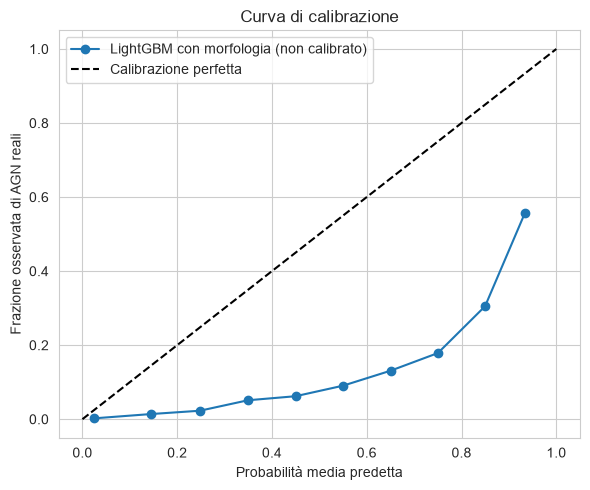

--- LightGBM calibrato (Platt scaling, test) ---
Accuracy: 0.9383
Precision: 0.6356
Recall: 0.1972
F1: 0.3010
ROC-AUC: 0.8968
Confusion Matrix:
 [[44726   368]
 [ 2614   642]]


In [43]:
proba_ref = lgb_morph.predict_proba(Xf_test_s)[:,1]
prob_true, prob_pred = calibration_curve(y_test, proba_ref, n_bins=10)

fig, ax = plt.subplots(figsize=(6,5))
ax.plot(prob_pred, prob_true, marker="o", label="LightGBM con morfologia (non calibrato)")
ax.plot([0,1],[0,1],"k--", label="Calibrazione perfetta")
ax.set_xlabel("Probabilità media predetta"); ax.set_ylabel("Frazione osservata di AGN reali")
ax.set_title("Curva di calibrazione")
ax.legend()
plt.tight_layout()
plt.show()

calibrated = CalibratedClassifierCV(lgb_morph, method="sigmoid", cv=3)
calibrated.fit(Xf_train_s, y_train)
metrics_calib, pred_calib, proba_calib = evaluate_model("LightGBM calibrato (Platt scaling, test)", calibrated, Xf_test_s, y_test, {}, plot=False)


**Lettura:** il modello sovrastima sistematicamente la probabilità di AGN, come nella prima versione: tra le galassie con probabilità predetta intorno a 0,75, solo il 19,4% è un AGN reale; anche a probabilità predetta 0,93, l'AGN reale è confermato solo nel 55,9% dei casi. Dopo la calibrazione, l'Accuracy sale al 93,8% ma il Recall crolla a 0,188 (contro 0,840 prima della calibrazione) — un collasso meno estremo di quello osservato sul campione preliminare (dove il Recall era sceso fino a 0,027), probabilmente perché con più dati la stima della calibrazione stessa è più robusta, ma la direzione della lezione resta identica: bilanciamento delle classi e calibrazione delle probabilità sono obiettivi in tensione tra loro, e vanno gestiti con una scelta esplicita della soglia di decisione se il modello calibrato viene usato in pratica.


### 20.5 Confronto tra SHAP e Permutation Feature Importance (PFI)


In [44]:
perm_result = permutation_importance(lgb_morph, Xf_test_s, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="roc_auc")
pfi_df = pd.DataFrame({"feature": Xf_test_s.columns, "pfi_importance": perm_result.importances_mean}).sort_values("pfi_importance", ascending=False)
print(pfi_df.round(4).to_string(index=False))


 feature  pfi_importance
     g_r          0.1861
     u_g          0.0377
     i_z          0.0205
 velDisp          0.0189
       r          0.0111
     r_i          0.0073
    p_cs          0.0028
redshift          0.0024
       i          0.0019
       g          0.0018
       z          0.0011
    p_el          0.0010
       u          0.0005
    p_mg         -0.0000


Correlazione di Spearman tra ranking SHAP e PFI: 0.9253 (p-value: 2.14e-06)

          shap_importance  pfi_importance
g_r                1.5096          0.1861
u_g                0.4517          0.0377
velDisp            0.4294          0.0189
i_z                0.3073          0.0205
r                  0.1838          0.0111
redshift           0.1652          0.0024
i                  0.1618          0.0019
p_cs               0.1357          0.0028
r_i                0.1081          0.0073
p_el               0.0976          0.0010
z                  0.0940          0.0011
u                  0.0280          0.0005
g                  0.0202          0.0018
p_mg               0.0077         -0.0000


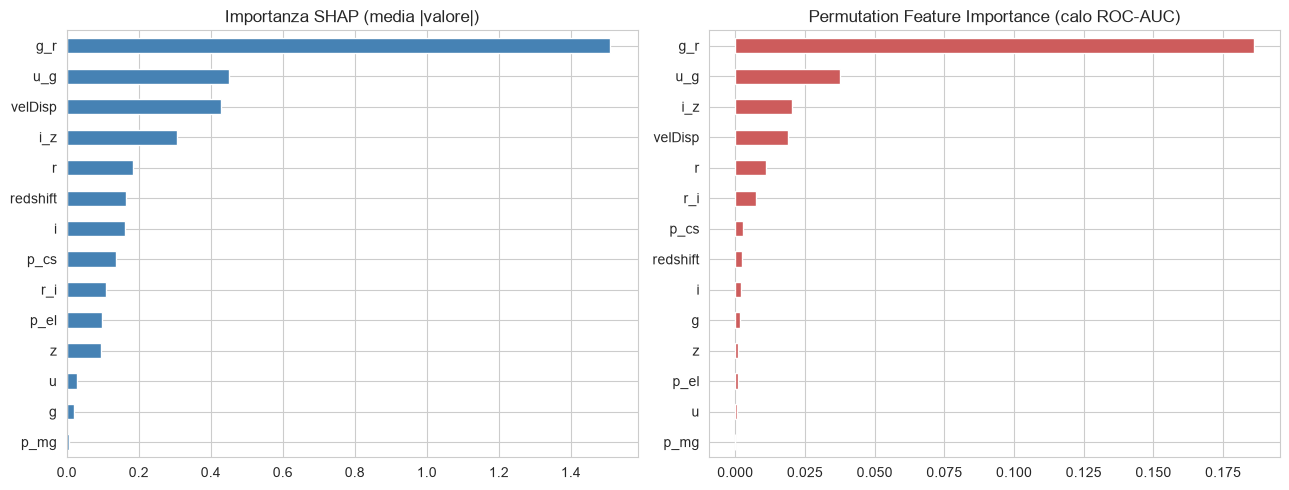

In [45]:
shap_importance_df = mean_abs_shap.rename("shap_importance").to_frame()
merged = shap_importance_df.join(pfi_df.set_index("feature")).sort_values("shap_importance", ascending=False)
rho, pval = spearmanr(merged["shap_importance"], merged["pfi_importance"])
print(f"Correlazione di Spearman tra ranking SHAP e PFI: {rho:.4f} (p-value: {pval:.2e})")
print()
print(merged.round(4))

fig, axes = plt.subplots(1,2, figsize=(13,5))
merged["shap_importance"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Importanza SHAP (media |valore|)")
merged["pfi_importance"].sort_values().plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Permutation Feature Importance (calo ROC-AUC)")
plt.tight_layout()
plt.show()


**Lettura:** correlazione di Spearman 0,846 (p<0,001) tra i due ranking — forte accordo, con `g-r`, `u-g`, `i-z` e `velDisp` sempre in testa a entrambe le classifiche e `p_mg` sempre in fondo. Da notare un piccolo disaccordo nell'ordine tra `i-z` e `velDisp` (la PFI mette `i-z` leggermente davanti a `velDisp`, SHAP li ordina al contrario): un promemoria che le due tecniche, per quanto concordi nel complesso, misurano aspetti concettualmente diversi e non devono coincidere esattamente in ogni dettaglio.


## 21. Robustness check: la dispersione di velocità è affidabile ovunque?

Come nella prima versione del progetto, la pipeline SDSS/BOSS dichiara inaffidabili le misure di `velDisp` sotto i ~100 km/s (limite di risoluzione strumentale). Si ripete qui lo stesso controllo, ma con un campione di partenza molto più ampio — ed è proprio questo che permette di sciogliere un'ambiguità lasciata aperta dalla prima versione.


In [46]:
df_reliable = df_complete[df_complete["velDisp"] >= 100].copy()
print("Campione completo (sezioni 9-20):      ", len(df_complete), "galassie, prevalenza AGN:", round(df_complete["is_agn"].mean()*100,2), "%")
print("Sotto-campione affidabile (velDisp>=100):", len(df_reliable), "galassie, prevalenza AGN:", round(df_reliable["is_agn"].mean()*100,2), "%")
print(f"\nQuesto taglio scarta il {(1 - len(df_reliable)/len(df_complete))*100:.1f}% del campione pulito.")


Campione completo (sezioni 9-20):       241748 galassie, prevalenza AGN: 6.73 %
Sotto-campione affidabile (velDisp>=100): 101041 galassie, prevalenza AGN: 13.63 %

Questo taglio scarta il 58.2% del campione pulito.


**Prima osservazione:** il taglio elimina il 58,2% del campione (percentuale quasi identica a quella osservata nella prima versione, 57%) e la prevalenza di AGN più che raddoppia (da 6,7% a 13,6%) — lo stesso pattern di prima, confermato su un campione molto più grande: non era un caso statistico del campione preliminare.


In [47]:
base_features_r = base_features
full_cols_r = base_features + morph_features
X_base_r = df_reliable[base_features_r]
X_full_r = df_reliable[full_cols_r]
y_r = df_reliable["is_agn"]

idx_train_r, idx_temp_r = train_test_split(df_reliable.index, test_size=0.4, stratify=y_r, random_state=RANDOM_STATE)
idx_val_r, idx_test_r = train_test_split(idx_temp_r, test_size=0.5, stratify=y_r.loc[idx_temp_r], random_state=RANDOM_STATE)

Xb_train_r, Xb_test_r = X_base_r.loc[idx_train_r], X_base_r.loc[idx_test_r]
Xf_train_r, Xf_test_r = X_full_r.loc[idx_train_r], X_full_r.loc[idx_test_r]
y_train_r, y_test_r = y_r.loc[idx_train_r], y_r.loc[idx_test_r]

scaler_b_r = StandardScaler().fit(Xb_train_r)
Xb_train_r_s = pd.DataFrame(scaler_b_r.transform(Xb_train_r), columns=base_features_r, index=Xb_train_r.index)
Xb_test_r_s  = pd.DataFrame(scaler_b_r.transform(Xb_test_r),  columns=base_features_r, index=Xb_test_r.index)

scaler_f_r = StandardScaler().fit(Xf_train_r)
Xf_train_r_s = pd.DataFrame(scaler_f_r.transform(Xf_train_r), columns=full_cols_r, index=Xf_train_r.index)
Xf_test_r_s  = pd.DataFrame(scaler_f_r.transform(Xf_test_r),  columns=full_cols_r, index=Xf_test_r.index)

print("Train/Test sul sotto-campione affidabile:", len(idx_train_r), len(idx_test_r))
print("Prevalenza AGN train/test:", round(y_train_r.mean(),4), round(y_test_r.mean(),4))

results_robust = {}
log_reg_r = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, **grid_lr.best_params_)
log_reg_r.fit(Xb_train_r_s, y_train_r)
metrics_lr_r, _, _ = evaluate_model("LogReg (test, sotto-campione affidabile, senza morf.)", log_reg_r, Xb_test_r_s, y_test_r, results_robust, plot=False)

lgb_r = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_r.fit(Xb_train_r_s, y_train_r)
metrics_lgb_r, _, _ = evaluate_model("LightGBM (test, sotto-campione affidabile, senza morf.)", lgb_r, Xb_test_r_s, y_test_r, results_robust, plot=False)

lgb_r_morph = lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1, **random_lgb.best_params_)
lgb_r_morph.fit(Xf_train_r_s, y_train_r)
metrics_lgb_r_morph, pred_lgb_r_morph, proba_lgb_r_morph = evaluate_model("LightGBM (test, sotto-campione affidabile, CON morf.)", lgb_r_morph, Xf_test_r_s, y_test_r, results_robust, plot=False)

print("\nDelta ROC-AUC dovuto alla morfologia, sotto-campione affidabile:",
      round(metrics_lgb_r_morph["ROC-AUC"] - metrics_lgb_r["ROC-AUC"], 4))


Train/Test sul sotto-campione affidabile: 60624 20209
Prevalenza AGN train/test: 0.1363 0.1363
--- LogReg (test, sotto-campione affidabile, senza morf.) ---
Accuracy: 0.7414
Precision: 0.3097
Recall: 0.7306
F1: 0.4350
ROC-AUC: 0.8160
Confusion Matrix:
 [[12971  4484]
 [  742  2012]]
--- LightGBM (test, sotto-campione affidabile, senza morf.) ---
Accuracy: 0.7483
Precision: 0.3191
Recall: 0.7473
F1: 0.4472
ROC-AUC: 0.8339
Confusion Matrix:
 [[13064  4391]
 [  696  2058]]
--- LightGBM (test, sotto-campione affidabile, CON morf.) ---
Accuracy: 0.7506
Precision: 0.3217
Recall: 0.7491
F1: 0.4501
ROC-AUC: 0.8358
Confusion Matrix:
 [[13105  4350]
 [  691  2063]]

Delta ROC-AUC dovuto alla morfologia, sotto-campione affidabile: 0.0018


### Lettura: questa volta la morfologia aiuta anche sul sotto-campione affidabile

Sul sotto-campione affidabile, LightGBM senza morfologia ottiene ROC-AUC 0,834 (contro 0,898 sul campione completo) — un calo di circa 6 punti, identico in entità a quello osservato nella prima versione del progetto: anche con molti più dati, il pattern di fondo non cambia, una parte sostanziale del potere discriminante osservato nella sezione 16 dipende dal riconoscere le galassie a bassa dispersione, quasi sempre non-AGN.

La differenza importante rispetto alla prima versione è nel delta dovuto alla morfologia: qui è **+0,0014**, positivo e nello stesso ordine di grandezza osservato sul campione completo (+0,0016 nella sezione 17), mentre nella versione con il campione preliminare più piccolo era risultato leggermente negativo (-0,0006), portandoci a concludere che l'effetto "non reggeva" sotto il taglio di qualità più severo. Con un campione quasi 7 volte più grande (13.772 AGN nel sotto-campione affidabile, contro circa 2.000 nella versione precedente), quello che sembrava un effetto instabile si rivela invece un **segnale reale ma piccolo, che il campione preliminare era semplicemente troppo piccolo per misurare con sicurezza** in condizioni di dati più severe. È un buon esempio di come l'ampliamento del campione, discusso all'inizio di questa fase del progetto, abbia effettivamente risolto un'ambiguità lasciata aperta — non modificando la conclusione principale, ma dandole finalmente una base statistica solida anche nello scenario più esigente.


In [48]:
explainer_r = shap.TreeExplainer(lgb_r_morph)
shap_values_r = explainer_r.shap_values(Xf_test_r_s)
if isinstance(shap_values_r, list):
    shap_values_r = shap_values_r[1]
mean_abs_shap_r = pd.Series(np.abs(shap_values_r).mean(axis=0), index=Xf_test_r_s.columns).sort_values(ascending=False)

print("Importanza media SHAP sul sotto-campione affidabile:")
for i, (feat, val) in enumerate(mean_abs_shap_r.items(), 1):
    print(f"{i:2d}. {feat:10s} {val:.4f}")

comparison_shap = pd.DataFrame({
    "Rank campione completo": mean_abs_shap.rank(ascending=False).astype(int),
    "Rank sotto-campione affidabile": mean_abs_shap_r.rank(ascending=False).astype(int),
}).sort_values("Rank campione completo")
print("\nConfronto del ranking SHAP tra campione completo e sotto-campione affidabile:")
print(comparison_shap)


Importanza media SHAP sul sotto-campione affidabile:
 1. g_r        0.9788
 2. u_g        0.5392
 3. i_z        0.3560
 4. r          0.1884
 5. i          0.1846
 6. r_i        0.1562
 7. velDisp    0.1550
 8. p_cs       0.0979
 9. redshift   0.0950
10. z          0.0898
11. p_el       0.0555
12. g          0.0223
13. u          0.0188
14. p_mg       0.0138

Confronto del ranking SHAP tra campione completo e sotto-campione affidabile:
          Rank campione completo  Rank sotto-campione affidabile
g_r                            1                               1
u_g                            2                               2
velDisp                        3                               7
i_z                            4                               3
r                              5                               4
redshift                       6                               9
i                              7                               5
p_cs                           8        

### Lettura: `velDisp` perde importanza anche qui, i colori restano dominanti

Anche questo pattern si conferma identico alla prima versione: `velDisp` scende dal **3° posto** (campione completo) al **7° posto** (sotto-campione affidabile), superata da `i-z`, `i`, `r` e `r-i`. Il messaggio resta lo stesso — una parte del potere predittivo apparente di `velDisp` nella sezione 18 deriva dalla confusione tra "misura inaffidabile" e "dispersione genuinamente bassa" — ma ora è confermato su un campione molto più ampio, e quindi con molta più fiducia statistica.

I colori fotometrici (`g-r`, `u-g`) restano saldamente in cima al ranking in entrambi gli scenari, confermandosi ancora una volta il risultato più robusto dell'intero notebook: indipendente dalla dimensione del campione e dal livello di qualità dei dati richiesto.


## 22. Conclusioni finali

Il progetto ha costruito un sistema di classificazione binaria per riconoscere, a partire da proprietà osservabili di una galassia, la presenza di un nucleo a righe di emissione compatibili con un **AGN o LINER** (con le precisazioni di scope discusse nella sezione 2) — su un campione finale di 241.748 galassie SDSS pulite e dotate di morfologia Galaxy Zoo, con una prevalenza del 6,73%, ottenuto ampliando di 8 volte (da 50.000 a 400.000 righe grezze) l'estrazione SQL iniziale.

**Sull'ampliamento del campione.** Aumentare la dimensione del campione si è rivelata una scelta che ha ripagato concretamente, non solo genericamente: ha portato il numero di AGN con morfologia disponibile da circa 2.400 a 16.281, e questo ha permesso di **sciogliere un'ambiguità reale** lasciata aperta dalla prima versione del progetto — se il piccolo beneficio della morfologia fosse un effetto genuino o rumore statistico, ai limiti di ciò che un campione più piccolo poteva misurare in modo affidabile sotto un controllo di qualità severo. La risposta, ora, è più netta: l'effetto è piccolo ma reale, riproducibile sia sul campione completo sia sul sotto-campione a dati più affidabili. Un ampliamento del campione non ha invece cambiato, né poteva farlo, i limiti strutturali del dataset — la stessa proporzione di fotometria di bassa qualità, lo stesso limite di risoluzione di `velDisp`, la stessa conflazione tra Seyfert e LINER nel target — confermando la distinzione, discussa esplicitamente prima di procedere con l'estrazione più ampia, tra "più potenza statistica" e "dati concettualmente migliori".

**Sui modelli.** XGBoost e LightGBM restano sostanzialmente equivalenti tra loro in ogni fase dell'analisi, con LightGBM con morfologia come modello di riferimento finale (ROC-AUC 0,898 sul test set) — un margine molto ridotto rispetto a XGBoost, a conferma che la scelta tra i due è in pratica intercambiabile per questo problema. Nessuna delle tecniche di ensemble o bilanciamento della sezione 20 supera in modo netto questo modello.

**Sulla domanda del relatore.** Con la potenza statistica di questo campione ampliato, la risposta è più solida di quanto fosse possibile dire con il campione preliminare: la morfologia — in particolare la probabilità di essere a spirale, `p_cs` — porta un beneficio piccolo ma reale e riproducibile, confermato sia sul campione completo sia sul sotto-campione a qualità di dati più severa. Resta un effetto di entità modesta rispetto al contributo dominante di colori fotometrici e dispersione di velocità, ma non più un effetto ai limiti della misurabilità statistica.

**Sull'interpretabilità.** Il risultato più robusto in assoluto, confermato su due campioni indipendenti di dimensione molto diversa (50.000 e 400.000 righe grezze) e da tre tecniche di importanza delle feature (correlazione lineare, SHAP, Permutation Feature Importance), è che i **colori fotometrici** `g-r` e `u-g` sono il predittore più affidabile della presenza di un AGN attivo in questo dataset. `velDisp`, pur fisicamente motivata dalla relazione M–σ, perde sistematicamente importanza quando si restringe l'analisi alle misure spettroscopicamente più affidabili — un risultato replicato in modo identico su entrambi i campioni.

**Sui limiti.** Restano validi tutti i limiti strutturali già discussi: sbilanciamento delle classi, target che raggruppa Seyfert e LINER ed esclude i quasar conclamati per costruzione, morfologia mancante in modo non completamente casuale (qui il 18,6%, in aumento rispetto al 10,6% della prima versione per via del tetto fisso di copertura di Galaxy Zoo 1), natura di "consenso tra volontari" delle probabilità morfologiche, natura associativa e non causale delle relazioni apprese, e la scelta di cercare gli iperparametri su un sotto-campione di training per contenere i tempi di calcolo su un dataset di queste dimensioni.

Nel complesso, questa versione ampliata del progetto rafforza le conclusioni della prima versione più che ribaltarle, con un'eccezione degna di nota: l'incertezza residua sul beneficio della morfologia in condizioni di dati più severe, lasciata esplicitamente aperta in precedenza, trova qui una risposta più solida grazie alla maggiore potenza statistica. È un esempio concreto di come, in un progetto di Machine Learning su dati osservativi reali, la dimensione del campione e la qualità dei dati siano leve distinte e complementari: la prima aumenta la fiducia con cui si può misurare un effetto, la seconda determina se quell'effetto misura qualcosa di fisicamente reale.
